# Traballo de Machine Learning - Sebastián Táboas Pazo 

**CAPTION** 

Neste código hai bastantes celas que tardan un tempo considerable en carregar (entre 30 s e 3 min) e a última sección que denomino `Apéndice Cross Validation en redes neuronais` nun ordenador relativamente potente tarda un promedio de ~7 horas --> **NON COMPILAR APÉNDICE**. Na sección 4 hai bastantes liñas comentadas tamén para reducir o custe computacional o que pode xerar problemas nalgún plot que dea crash (erro tipo variable not defined) ou que simplemente non plotee nada.

## 0. Introdución
A descripción do noso dataset escollido na páxina de kaggle reza:

"A cafeína é o o principal estimulante do sistema nervioso central consumido no mundo. Ademais, os perfiles biofísicos individuais responden significativamente distinto segundo nas enzimas hepáticas (determinada polos xenes, CYP1A2 clearance), a co-inxestión de azucre na dieta e as deficiencias agudas de descanso nocturno. Cando na circulación límpase a cafeína, aparece un efecto rebote dos receptores de adenosina que reacciona coa hipoglucemia reactiva xerando fatiga vespertina intensa, conxestión mental, tremores e ansiedade situacional.

This dataset provides cross-sectional pharmacokinetic and subjective cognitive telemetry for 8,000 individuals, capturing beverage consumption patterns, physiological stress markers, and resulting crash dynamics."

O noso obxectivo será pretender predicir o risco dun tipo de crash, <<crash_risk_level>>, mediante o resto de información situacional e biolóxica do dataset. Levaremos a cabo 
as predicións mediante Scikit-Learn (ferramente de machine learning mediante métodos estatísticos regresivos) e con tensorflow.keras (keras é unha ferramenta de ML que permite construír e entrenar redes neuronais). Ademais empregamos seaborn para representación de datos e visualización de correlacións. Poderiamos facer outras predicións como valores de dor cardíaca aguda, valores de nerviosismo e ansiedade ou da gravidade de crash. Precisamente tamén veremos moi brevemente a puntuación de gravidade con sklearn.


## 1. Depuración de datos

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import sys
import os
sys.path.append(os.getcwd())

In [64]:
# https://www.kaggle.com/datasets/samartalwar/caffeine-crash-and-jitters-energy-drinks-and-anxiety
df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv')
df.head()

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


In [65]:
df.info() # sinala automaticamente onde hai valores nulos e o tipo de columna

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   user_id                   8000 non-null   str    
 1   age                       8000 non-null   int64  
 2   gender                    8000 non-null   str    
 3   cyp1a2_metabolizer_type   8000 non-null   str    
 4   caffeine_tolerance        8000 non-null   str    
 5   baseline_anxiety_score    8000 non-null   float64
 6   prior_sleep_hours         8000 non-null   float64
 7   daily_hydration_liters    8000 non-null   float64
 8   primary_caffeine_source   8000 non-null   str    
 9   caffeine_mg               8000 non-null   int64  
 10  sugar_grams               8000 non-null   float64
 11  consumption_duration_min  8000 non-null   int64  
 12  heart_rate_spike_bpm      8000 non-null   float64
 13  jitters_intensity_score   8000 non-null   float64
 14  acute_anxiety_score

In [66]:
# agora vemos datos máis pormenorizadamente, e.g., para <<crash_risk_level>> porque pretenderemos predicila, podemos ver calquera das columnas que nos devolve df.info()
print(f"{'crash_risk_level'}: \n{df['crash_risk_level'].describe()}")
df.crash_risk_level.unique()

crash_risk_level: 
count                          8000
unique                            4
top       Moderate Crash & Lethargy
freq                           2426
Name: crash_risk_level, dtype: object


<StringArray>
[      'Mild Afternoon Fatigue', 'Sustained / Negligible Crash',
    'Moderate Crash & Lethargy',   'Severe Crash & Tachycardia']
Length: 4, dtype: str

Vemos que no noso dataset non temos columnas que conteñan celas baleiras. As columnas <<user_id>>, << gender>>, <<cyp1a2_metabolizer_type>>, <<caffeine_tolerance>>, <<primary_caffeine_source>> e <<crash_risk_level>> son strings. Estes datos teremos que depuralos, no caso de <<user_id>> non nos aportará nada de información e <<crash_risk_level>> non será necesario tocala en principio porque aplicaremos as nosas técnicas tal cal sobre a variable str.

In [67]:
for i in range(1,len(df.columns)):
    if df[df.columns[i]].dtypes == 'str':
        print(f'Na columna <<{df.columns[i]}>> pódense tomar os seguintes valores {df[df.columns[i]].unique()}')

s = 0 # isto serve para contar cantos suxeitos satisfan certo valor
for i in range(len(df)):
    if df['crash_risk_level'].iloc[i] == 'Severe Crash & Tachycardia':
        s += 1
print(f'En gender hai {s} Non-Binary') # podo poñer isto máis xeral 2377 , 1036, 2426, 2161

Na columna <<gender>> pódense tomar os seguintes valores <StringArray>
['Female', 'Male', 'Non-Binary']
Length: 3, dtype: str
Na columna <<cyp1a2_metabolizer_type>> pódense tomar os seguintes valores <StringArray>
['Fast', 'Normal', 'Slow']
Length: 3, dtype: str
Na columna <<caffeine_tolerance>> pódense tomar os seguintes valores <StringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str
Na columna <<primary_caffeine_source>> pódense tomar os seguintes valores <StringArray>
[         'Brewed Drip Coffee',   'Energy Drink (Sugar-Free)',
   'Energy Drink (Full Sugar)',      'Pre-Workout Supplement',
 'Espresso / Specialty Drinks',          'Matcha / Green Tea']
Length: 6, dtype: str
Na columna <<crash_risk_level>> pódense tomar os seguintes valores <StringArray>
[      'Mild Afternoon Fatigue', 'Sustained / Negligible Crash',
    'Moderate Crash & Lethargy',   'Severe Crash & Tachycardia']
Length: 4, dtype: str
En gender hai 2161 Non-Binary


Segundo os valores que vemos, as variables <<cyp1a2_metabolizer_type>> e <<caffeine_tolerance>> pódense poñer perfectamente como datos numéricos cun diccionario. Para os casos << gender>>, <<primary_caffeine_source>> e <<crash_risk_level>> o mellor é traballar con variables dummies. Decatémonos que a primeira columna non nos aporta ningunha información, é un código de identificación do suxeito avaliado. O mellor é eliminalo.

In [68]:
gender_dummies = pd.get_dummies(df['gender'], prefix='gender', dtype=int)
primary_caffeine_source_dummies = pd.get_dummies(df['primary_caffeine_source'], prefix='primary_caffeine_source', dtype=int)
crash_risk_level_dummies = pd.get_dummies(df['crash_risk_level'], prefix='crash_risk_level', dtype=int)
# En principio non será necesario para os calculos utilizar crash_risk_level_dummies, si será interesante para poñer a matriz de correlación

df['cyp1a2_metabolizer_type'] = df['cyp1a2_metabolizer_type'].map({'Fast':2, 'Normal':1, 'Slow':0})
df['cyp1a2_metabolizer_type'] = df['cyp1a2_metabolizer_type'].fillna(0) # por se acaso aparecen NaN pois que sexan lexibles numericamente

df['caffeine_tolerance'] = df['caffeine_tolerance'].map({'High':2, 'Moderate':1, 'Low':0})
df['caffeine_tolerance'] = df['caffeine_tolerance'].fillna(0)

df = df.rename(columns = {'cyp1a2_metabolizer_type': 'cyp1a2_metabolizer_speed_type'})

# como na sección seguinte aínda nos vai interesar utilizar o noso dataframe df con algunhas variables str utilizamos unha copia para cando
# sexa necesario empregar os dummies que será nos puntos 3 e 4. A columna <<user_id>> só nos entorpece; eliminámola directamente.
Df = df.copy()
Df = pd.concat([Df.drop(columns=['user_id','gender','primary_caffeine_source']),
                                gender_dummies, primary_caffeine_source_dummies],
                                axis=1)

Df.head()


,age,cyp1a2_metabolizer_speed_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,...,crash_risk_level,gender_Female,gender_Male,gender_Non-Binary,primary_caffeine_source_Brewed Drip Coffee,primary_caffeine_source_Energy Drink (Full Sugar),primary_caffeine_source_Energy Drink (Sugar-Free),primary_caffeine_source_Espresso / Specialty Drinks,primary_caffeine_source_Matcha / Green Tea,primary_caffeine_source_Pre-Workout Supplement
0,27,2,2,2.4,7.0,2.29,138,8.7,36,2.0,...,Mild Afternoon Fatigue,1,0,0,1,0,0,0,0,0
1,57,2,0,9.1,7.1,2.41,164,0.0,3,2.4,...,Sustained / Negligible Crash,1,0,0,0,0,1,0,0,0
2,39,1,0,2.9,5.1,2.07,179,36.9,10,3.8,...,Moderate Crash & Lethargy,0,1,0,0,1,0,0,0,0
3,34,2,1,3.8,5.0,2.34,408,1.6,3,6.8,...,Severe Crash & Tachycardia,1,0,0,0,0,0,0,0,1
4,22,0,2,2.0,6.3,1.92,170,50.2,11,2.0,...,Severe Crash & Tachycardia,1,0,0,0,1,0,0,0,0


Por último comprobamos que non haxa dexeneración nos nosos datos (filas duplicadas).

In [69]:
if df.duplicated().sum() > 0:
    print(f'Hai {df.duplicated().sum()} filas duplicadas (dexeneración de datos) no DataFrame. Logo temos que depurar estos datos duplicados, e.g. eliminándoos')
else:
    print('Non hai filas duplicadas. Nada que facer.')

Non hai filas duplicadas. Nada que facer.


## 2. Representacións estatísticas

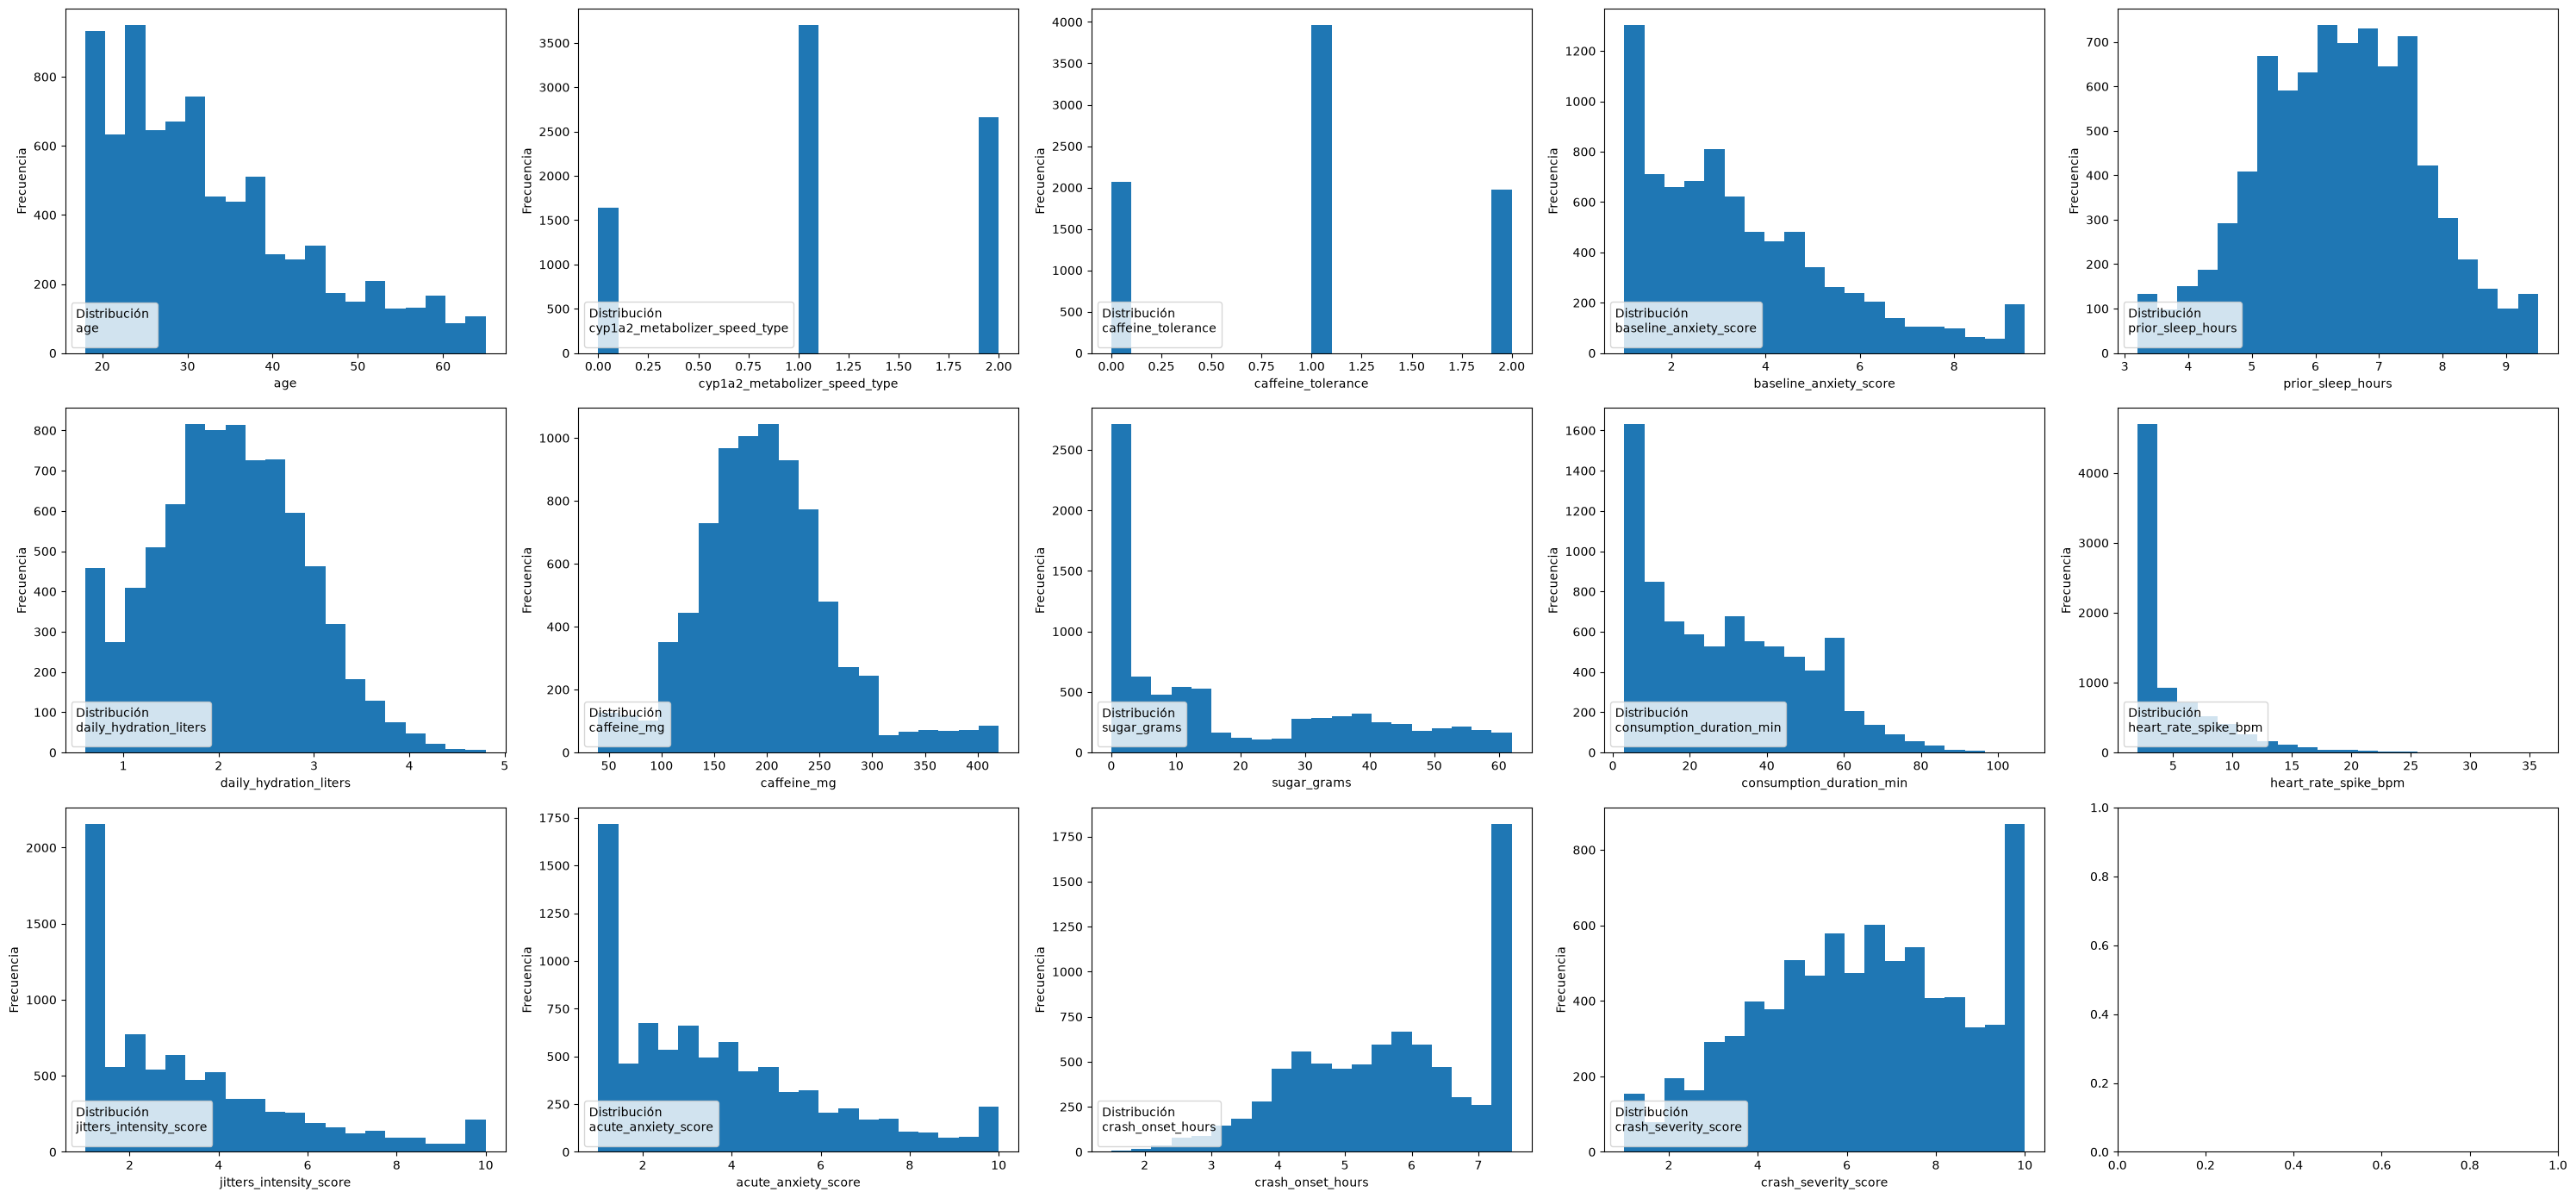

In [8]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
fig, axs = plt.subplots(3,5, figsize=(30, 14))

num_vert = 0; num_hor = 0
for cols in numeric_cols: 
    
    axs[num_vert,num_hor].hist(df[cols], bins=20)
    axs[num_vert,num_hor].legend( title=f'Distribución \n{cols}', loc='lower left')
    axs[num_vert,num_hor].axes.get_xaxis().set_visible(True)
    axs[num_vert,num_hor].axes.get_yaxis().set_visible(True)
    axs[num_vert,num_hor].set_xlabel(f'{cols}')
    axs[num_vert,num_hor].set_ylabel('Frecuencia')
    
    num_hor += 1
    if num_vert == 0 and num_hor == 5:
            num_vert = 1
            num_hor = 0

    elif num_vert == 1 and num_hor == 5:
            num_vert = 2
            num_hor = 0    
        
plt.tight_layout()
fig.show()

Así a vista podemos ver que as nosas variables distribúense en xeral nalgunha clase de distribución exponencial ou gaussiana. Na gran maioría o dato da moda resulta atípico, aínda que realmente podemos pensar que isto é realmente un punto que nos indica que as variables están fortemente ligadas, e.g., que moita xente teña un consumo de azucre próximo a 0 gramos pode xustificar que a maioría dos accidentes ocorran máis de 6 horas despois da inxesta se é que o azucre funciona como un catalizador; ou, máis obvio, que a gran maioría de persoas non se autoperciban síntomas de tremores pode coincidir con non detectar unha $\Delta$ BPM tamén na gran maioría. Nos casos gaussianos atopamos unha distribución interesante sobre hábitos de vida como a cantidade de auga que se bebe como as de horas que durmen. Tamén nos decatamos que a gran maioría de pacentes foron precisamente xente xove (menores de 34 anos) aos que se asocia un maior número de consumo de bebidas enerxéticas fronte a formas tradicionais de consumo de cafeína (café ou té).

In [9]:
# Pode ser interesante revisar a media e a moda dalgunhas distribucións, por exemplo:
distrib = ('prior_sleep_hours', 'daily_hydration_liters', 'caffeine_mg' ,'crash_onset_hours', 'crash_severity_score')
for cat in distrib:
    print(f'En {cat} a media é {df[cat].mean():.2f} e a moda é {df[cat].mode().tolist()[0]}')

En prior_sleep_hours a media é 6.38 e a moda é 6.7
En daily_hydration_liters a media é 2.11 e a moda é 0.6
En caffeine_mg a media é 198.04 e a moda é 197
En crash_onset_hours a media é 5.65 e a moda é 7.5
En crash_severity_score a media é 6.29 e a moda é 10.0


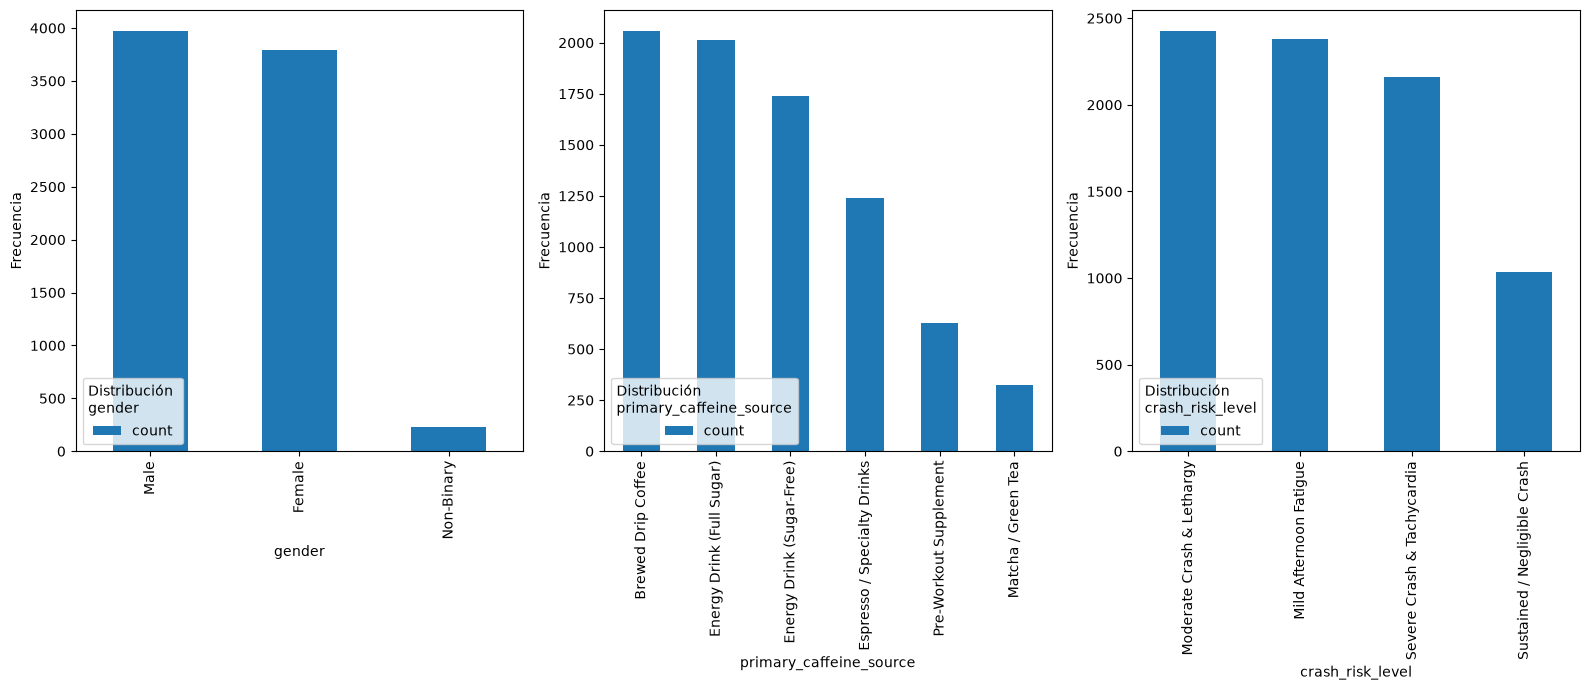

In [10]:
categorical_cols = df.select_dtypes(include=['object']).columns

fig, axs = plt.subplots(1,3, figsize=(16, 7))

num_hor = 0
for col in categorical_cols[1:]:
    df[col].value_counts().plot(kind='bar', ax=axs[num_hor])
    axs[num_hor].legend(title=f'Distribución \n{col}', loc='lower left')
    axs[num_hor].set_xlabel(col)
    axs[num_hor].set_ylabel('Frecuencia')
    num_hor += 1
        
plt.tight_layout()
fig.show()

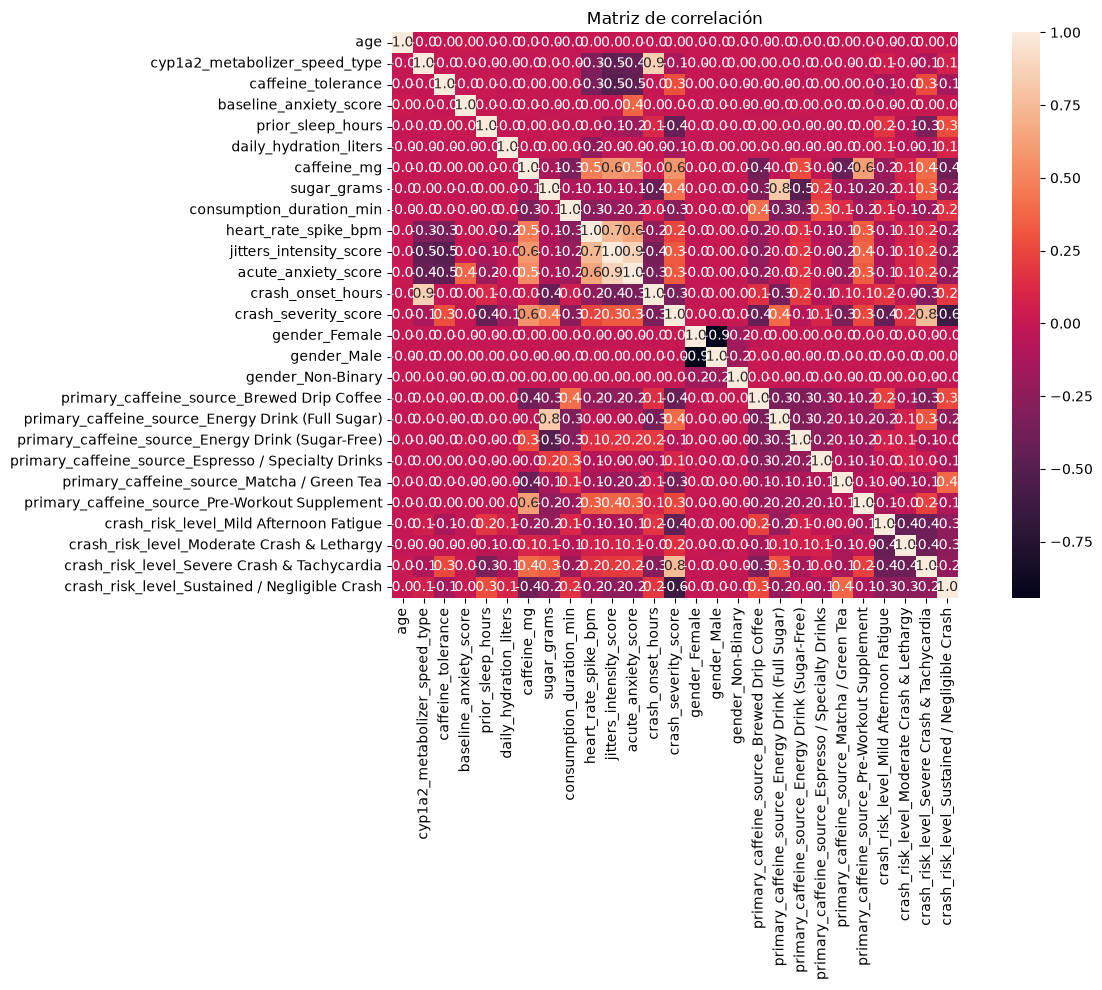

In [11]:
# Aquí empregamos o DataFrame Df con todas as columnas str traducidas ou empregando os dummies respectivos; isto é necesario
# para facer correlacións numéricas.

# Mapa de calor da matriz de correlación do noso dataframe completamente numérico
plt.figure(figsize=(14, 10))
sns.heatmap(pd.concat([Df.drop(columns=['crash_risk_level']),crash_risk_level_dummies],axis=1).select_dtypes(include='number').corr(), 
            annot=True, fmt='.1f', square=True#, cmap='coolwarm'
            )
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

Vemos que na diagonal aparecen 3 cadradados pequenos de correlación negativa moi significativa, isto derívase de que son as submatrices das variables dummies que son autoexcluíntes. Obviamente non pode haber un suxeito home e muller á vez (obviando identificacións de xénero fluído) ou que alguén teña dúas gravidades distintas no crash. 

Vemos a continuación un pouco máis en detalle algunha variable significativa nas predicións.

In [12]:
# Imos facer categorías para <<caffeine_mg>> e <<sugar_grams>> para comparalas con <<crash_risk_level>> 
# As categorías escolloas así un pouco a ollo, a cafeína semella unha gaussiana así facemos division 25 50 25
# e o azucre é exponencial ou incluso cadrada se obviamos o 0, escollemos unha equiseparación 33.33 33.33 33.33
# Tamén compararemos as <<primary_caffeine_source>> con <<crash_risk_level>> 

p25, p75 = df["caffeine_mg"].quantile([0.25, 0.75])
p33, p66 = df["sugar_grams"].quantile([0.3333, 0.6666])

def categorize_caffeine(score): # en cuartiles (aínda que o primer 25 chega aos 157mg que me parece pila)
    # corrixome unha enerxética zero do Día (a que me estou tomando agora mesmo) pequena (250ml) ten 31mg/100ml --> 77,5 mg
    # logo, como a maioría de enerxéticas son de 500 ml, cunha cantidade semellante de cafeína ten uns 150 mg 
    if score <= p25: # <25%
        return 'Low'
    elif score <= p75: # 25 - 75%
            return 'Medium'
    else:
        return 'High' # >75%

def categorize_sugar(score): # en terciles 
    if score <= p33: # <33.33%
        return 'Low'
    elif score <= p66:
            return 'Medium' # 33.33-66.66%
    else:
        return 'High' # >66.66%

caffeine_level = df['caffeine_mg'].apply(categorize_caffeine)
sugar_level = df['sugar_grams'].apply(categorize_sugar)

corr_cafe_sugar_source = pd.concat([caffeine_level, sugar_level, df['primary_caffeine_source'],df['crash_risk_level']], axis=1)
corr_cafe_sugar_source.head()

,caffeine_mg,sugar_grams,primary_caffeine_source,crash_risk_level
0,Low,Medium,Brewed Drip Coffee,Mild Afternoon Fatigue
1,Medium,Low,Energy Drink (Sugar-Free),Sustained / Negligible Crash
2,Medium,High,Energy Drink (Full Sugar),Moderate Crash & Lethargy
3,High,Low,Pre-Workout Supplement,Severe Crash & Tachycardia
4,Medium,High,Energy Drink (Full Sugar),Severe Crash & Tachycardia


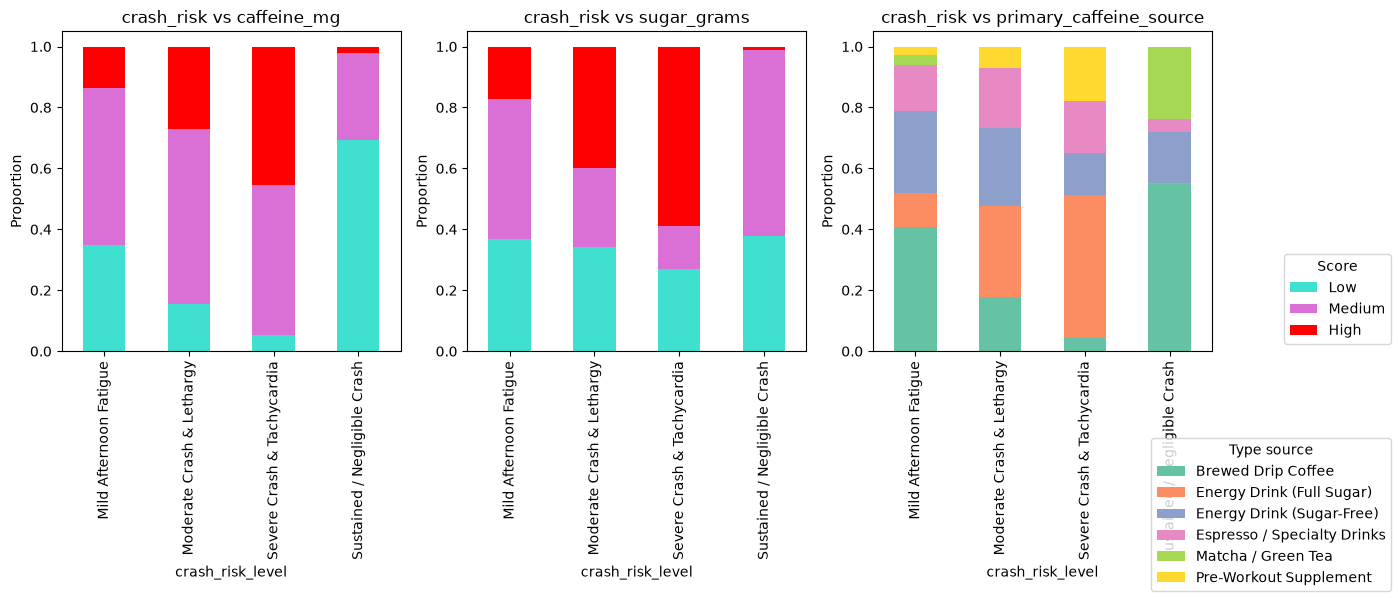

In [13]:
Scores = ('caffeine_mg', 'sugar_grams')
Rangos = ('Low', 'Medium', 'High')
cores = ['turquoise', 'orchid', 'r']

fig, axs = plt.subplots(1, 3, figsize=(14, 6))

for i, score in enumerate(Scores):
    score_distribution = (
        corr_cafe_sugar_source
        .groupby('crash_risk_level')[score]
        .value_counts(normalize=True)
        .unstack()
        .reindex(columns=Rangos, fill_value=0)
        )

    score_distribution.plot(
        kind='bar',
        stacked=True,
        ax=axs[i],
        color=cores,
        legend=False
        )
    
    axs[i].set_title(f'crash_risk vs {score}')
    # axs[i].set_xlabel('Crash risk level') # non creo que falla falta, é bsatante intuitiva a gráfica
    axs[i].set_ylabel('Proportion')

# facemos un plot especial para poder ver stackeadas dúas variables str por proporción
crash_vs_source = pd.crosstab(corr_cafe_sugar_source['crash_risk_level'], corr_cafe_sugar_source['primary_caffeine_source'], normalize='index')
cores = sns.color_palette('Set2', n_colors=crash_vs_source.shape[1])
crash_vs_source.plot(kind='bar', stacked=True, ax=axs[2], color=cores, legend=False)
axs[2].set_title(f'crash_risk vs primary_caffeine_source')
axs[2].set_ylabel('Proportion')

handles, label_1 = axs[0].get_legend_handles_labels()
handles1, label_2 = axs[2].get_legend_handles_labels()
fig.legend(handles, label_1, title='Score', loc='center right')
fig.legend(handles1, label_2, title='Type source', loc='lower right')

plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.show()

Agora, previo a proceder ás dúas análises de predicción da variable <<crash_risk_level>> debemos separar as nosas mostras de datos en datos de entrenamento e de testeo. Será necesario que utilizemos o dataframe onde substituímos as columnas str polos dummies respectivos (Df) que serán sempre os datos de interese no resto do noso estudo.

In [14]:
y1 = Df.crash_risk_level

labels_1 = ['Mild Afternoon Fatigue', # son os elementos de y1, será necesario telo definido. De momento non sei se fará falta un labels_2
    'Moderate Crash & Lethargy',
    'Severe Crash & Tachycardia',
    'Sustained / Negligible Crash'] 

In [15]:
x1 = Df.drop(columns=['crash_risk_level'])

In [16]:
split = round(x1.shape[0]*0.80) # todas as X son do mesmo tamaño, non distinguimos, 80% de entreno e 20% de testeo
x1_train, x1_test = x1[:split], x1[split:]
y1_train, y1_test = y1[:split], y1[split:]

## 3. Análise con sklearn (regresión loxística)

Primeiro normalizo as variables

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x1_train_scaled = scaler.fit_transform(x1_train)
x1_test_scaled = scaler.transform(x1_test)

#### 3.0.1 Modelo Linear

Toca empezar a crear modelos, o primeiro será linear e empregarei un cálculo a man da optimización do hiperparámetro alpha, este é bastante pequeno así que para reducir o costo computacional xa o teño posto cerquiña do valor real que calcula (estiven 12 minutos esperando cunha partición máis fina nun intervalo máis grande XoX)

In [18]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import cross_val_score

alpha = np.arange(1e-15, 0.000001, 0.00000005)
val_scores = np.zeros(len(alpha))

for i, a in enumerate(alpha):
    model_cross = SGDClassifier(
            loss='hinge', penalty='l2', alpha=a, random_state=100
        )
    score = cross_val_score(model_cross, x1_train_scaled, y1_train, cv=5)
    val_scores[i] = score.mean()

ind = np.argmax(val_scores)
print('O mellor valor de alpha é', alpha[ind])


O mellor valor de alpha é 6.500000009999999e-07


In [19]:
model_linear = SGDClassifier(loss='hinge', penalty='l2', alpha=alpha[ind])
model_trained_1 = model_linear.fit(x1_train_scaled, y1_train)

y1_hat_train_1 = model_trained_1.predict(x1_train_scaled)
y1_hat_test_1 = model_trained_1.predict(x1_test_scaled)

In [20]:
from sklearn.metrics import r2_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

print(f'A exactitude de predición do modelo linear no conxunto de adestramento é {accuracy_score(y1_train, y1_hat_train_1):.4f}')
print(f'A exactitude de predición do modelo linear no conxunto de teste é {accuracy_score(y1_test, y1_hat_test_1):.4f}')

print(
    classification_report(
        y1_test,
        y1_hat_test_1,
        target_names=labels_1
    )
)

A exactitude de predición do modelo linear no conxunto de adestramento é 0.7770
A exactitude de predición do modelo linear no conxunto de teste é 0.7638
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.57      0.65      0.61       443
   Moderate Crash & Lethargy       0.66      0.57      0.61       509
  Severe Crash & Tachycardia       0.99      0.99      0.99       435
Sustained / Negligible Crash       0.97      0.98      0.97       213

                    accuracy                           0.76      1600
                   macro avg       0.80      0.80      0.80      1600
                weighted avg       0.77      0.76      0.76      1600



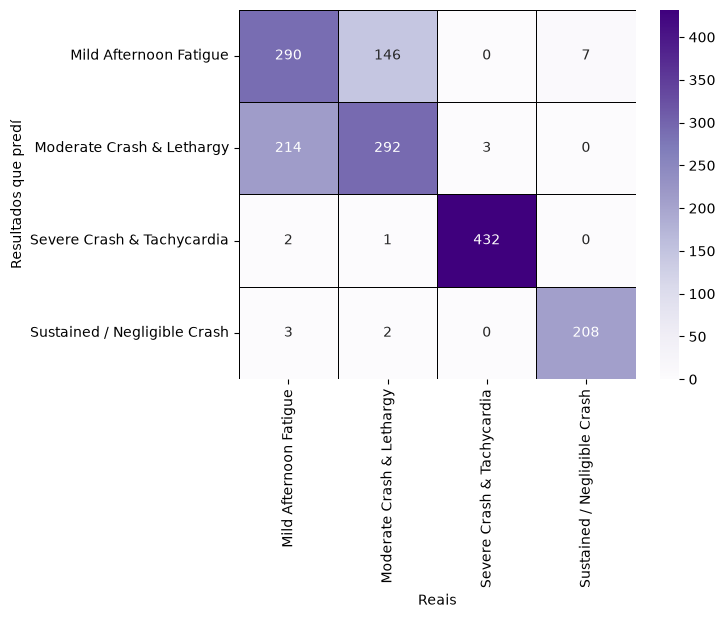

In [21]:
from sklearn.metrics import confusion_matrix

cm_1 = confusion_matrix(y1_test, y1_hat_test_1, labels=labels_1)

sns.heatmap(cm_1, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1) #Graficamos la matriz de confusión en escala de colores violeta, hacemos que aparezcan los valores de los resultados (en forma de números enteros) y sus clases y que la separación de los resultados sea una línea negra
plt.ylabel('Resultados que predí') #Ponemos título al eje y
plt.xlabel('Reais') #Ponemos título al eje x
plt.show() #Hacemos que se muestre el mapa de calor

#### 3.0.2 Modelo RBF
Modelo Radial Basis Function, é un modelo gaussiano con fronteiras non-lineares, espérase que se axuste moito mellor que unha recta ao considerar precisamente asociacións non lineares

In [22]:
from sklearn.svm import SVC

model_rbf = SVC(
    kernel='rbf',
    C=1.0,
    gamma='scale'
)

model_trained_2 = model_rbf.fit(x1_train_scaled, y1_train)

y1_hat_train_2 = model_trained_2.predict(x1_train_scaled)
y1_hat_test_2 = model_trained_2.predict(x1_test_scaled)

In [23]:
print(f'A exactitude de predición do modelo lin no conxunto de adestramento é {accuracy_score(y1_train, y1_hat_train_2):.4f}')
print(f'A exactitude de predición do modelo lin no conxunto de teste é {accuracy_score(y1_test, y1_hat_test_2):.4f}')

print(
    classification_report(
        y1_test,
        y1_hat_test_2,
        target_names=labels_1
    )
)

A exactitude de predición do modelo lin no conxunto de adestramento é 0.9608
A exactitude de predición do modelo lin no conxunto de teste é 0.9244
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.90      0.94      0.92       443
   Moderate Crash & Lethargy       0.91      0.94      0.92       509
  Severe Crash & Tachycardia       0.96      0.92      0.94       435
Sustained / Negligible Crash       0.94      0.86      0.90       213

                    accuracy                           0.92      1600
                   macro avg       0.93      0.92      0.92      1600
                weighted avg       0.93      0.92      0.92      1600



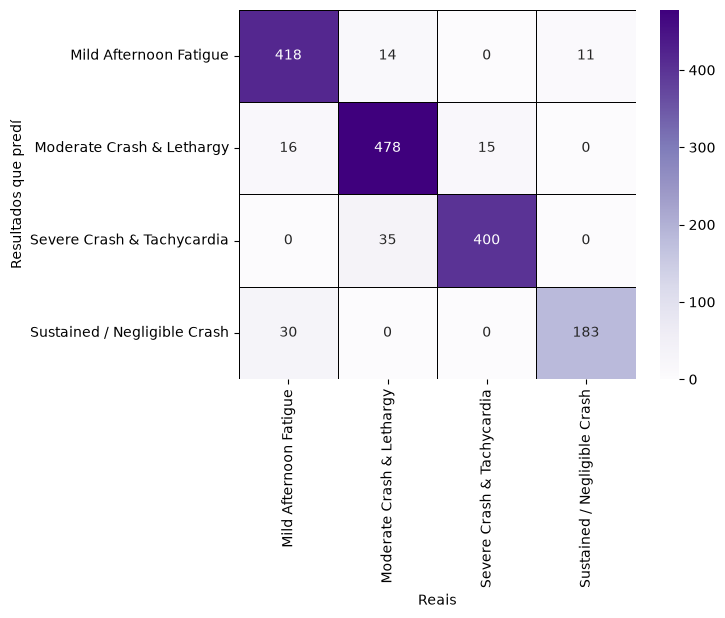

In [24]:
cm_2 = confusion_matrix(y1_test, y1_hat_test_2, labels=labels_1)

sns.heatmap(cm_2, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

### 3.1 Análise sen sesgo

In [25]:
# o nome da sección é por poñer algo, non sei que poñer.
from sklearn.feature_selection import mutual_info_classif

mi = mutual_info_classif(
    x1_train_scaled,
    y1_train,
    random_state=100
)

for col, val in sorted(zip(x1.columns, mi),
                       key=lambda x1: x1[1],
                       reverse=True):
    print(col, round(val,4))

crash_severity_score 1.3402
caffeine_mg 0.217
sugar_grams 0.1812
primary_caffeine_source_Brewed Drip Coffee 0.0941
prior_sleep_hours 0.0891
primary_caffeine_source_Energy Drink (Full Sugar) 0.0816
crash_onset_hours 0.0753
jitters_intensity_score 0.0701
primary_caffeine_source_Matcha / Green Tea 0.0641
acute_anxiety_score 0.0559
caffeine_tolerance 0.0411
heart_rate_spike_bpm 0.0381
consumption_duration_min 0.0333
primary_caffeine_source_Pre-Workout Supplement 0.0331
primary_caffeine_source_Espresso / Specialty Drinks 0.0271
cyp1a2_metabolizer_speed_type 0.0227
primary_caffeine_source_Energy Drink (Sugar-Free) 0.0196
daily_hydration_liters 0.0088
baseline_anxiety_score 0.0071
gender_Male 0.0049
gender_Non-Binary 0.0002
age 0.0
gender_Female 0.0


aquí vemos que a columna <<crash_severity_score>> ten un 1.34 de correlación o que quere dicir que lle está "chivando" (que é ao que lle chamo sesgo) moita información ao modelo, o seu sería ver como se comporta sen empregar esta columna, logo, repetindo considerando ese caso, i.e., facendo un drop no noso dataframe definindo de novo as x's e as y's

In [26]:
y2 = Df.crash_risk_level # satisfaise que y1 == y2; pero por poder facelos distinguibles
x2 = Df.drop(columns=['crash_risk_level','crash_severity_score'])

split = round(x2.shape[0]*0.80) # todas as X son do mesmo tamaño, non distinguimos, 80% de entreno e 20% de testeo
x2_train, x2_test = x2[:split], x2[split:]
y2_train, y2_test = y2[:split], y2[split:]

x2_train_scaled = scaler.fit_transform(x2_train)
x2_test_scaled = scaler.transform(x2_test)

#### 3.1.1 Estimación, training e resultados do Modelo Linear/Loxístico linear

Agora imos predecir adecuadamente os parámetros de todos os nosos modelos. En vez de empregar un cálculo a man como se fixo antes para o caso linear empregamos unha función de sklearn que se chama `GridSearchCV`. Primeiro vemos o caso da linear a ver que tal se axusta e de ser necesario correximos o `loss`, que antes usamos `loss = hinge` que é o caso linear, e o `penalty` que os escollimos anteriormente sen xustificación. É de esperar que o axuste loxístico (`loss = log_loss`) sexa mellor que linear, así que comparamos o valor do `best_score_` para determinalo; representaremos só os resultados do mellor entre os dous.

In [27]:
from sklearn.model_selection import GridSearchCV

param_linear = {
    'loss': ['hinge'],
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [1e-5, 1e-4, 1e-3, 1e-2, 5e-3]
}

grid_linear = GridSearchCV(
    estimator = SGDClassifier(random_state=100),
    param_grid = param_linear,
    cv = 10, # é o número de cross validations que fai o algoritmo; se poño moitas posibilidades no param_grid é necesario aumentalo, pero aumenta moitisimo o custe computacional
    scoring = 'f1_macro', # neste caso a columna <<crash_risk_level>> ten as proporcións de datos 2377, 1036, 2426, 2161 --> 29.7, 12.9, 30.3, 27.0 %
    # non é unha diferenza moi significativa polo que tanto empregar 'accuracy' como 'f1_macro' son boas opcións; escollo a segunda para balancear mellor
    n_jobs = -1 # emprega todos os núcleos da cpu: moito máis rápido pero pode saturar outros programas abertos
)

grid_linear.fit(x2_train_scaled, y2_train)
best_model_linear = grid_linear.best_estimator_ # escollemos automaticamente o modelo mellor estimado (o de mellores parámetros)

param_log = {
    'loss': ['log_loss'], # usar 'modified_huber' dá resultados moi lixeiramente mellores, pero non é tipo loxístico
    'penalty': ['l2', 'l1', 'elasticnet'],
    'alpha': [1e-5, 1e-4, 1e-3, 1e-2, 5e-3]
}

grid_log = GridSearchCV(
    estimator = SGDClassifier(random_state=100),
    param_grid = param_log,
    cv = 10, 
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_linear.fit(x2_train_scaled, y2_train)
grid_log.fit(x2_train_scaled, y2_train)
best_model_log = grid_log.best_estimator_

# o mellor modelo escóllese precisamente con aquel que entre todas as combinacións de parámetros dados posibles teña o scoring (f1-macro) máximo, 
# cada scoring é media de todas as validacións cruzadas para esos parámetros
print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_linear.best_score_:.4f}')
print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_log.best_score_:.4f}')
if grid_log.best_score_ > grid_linear.best_score_:
    print('A regresión loxística axústase mellor que a linear.')
else:
    print('A regresión linear axústase mellor que a loxística.')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.6697
O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.7467
A regresión loxística axústase mellor que a linear.


In [28]:
y2_hat_train_1 = best_model_log.predict(x2_train_scaled)
y2_hat_test_1 = best_model_log.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo Loxístico son {grid_log.best_params_}')
print(f'A exactitude de predición do modelo Loxístico no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_1):.4f}')
print(f'A exactitude de predición do modelo Loxístico no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_1):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_hat_test_1,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo Loxístico son {'alpha': 0.005, 'loss': 'log_loss', 'penalty': 'l1'}
A exactitude de predición do modelo Loxístico no conxunto de adestramento é 0.7439
A exactitude de predición do modelo Loxístico no conxunto de teste é 0.7331

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.65      0.73      0.69       443
   Moderate Crash & Lethargy       0.71      0.62      0.66       509
  Severe Crash & Tachycardia       0.82      0.89      0.85       435
Sustained / Negligible Crash       0.80      0.69      0.74       213

                    accuracy                           0.73      1600
                   macro avg       0.74      0.73      0.74      1600
                weighted avg       0.73      0.73      0.73      1600



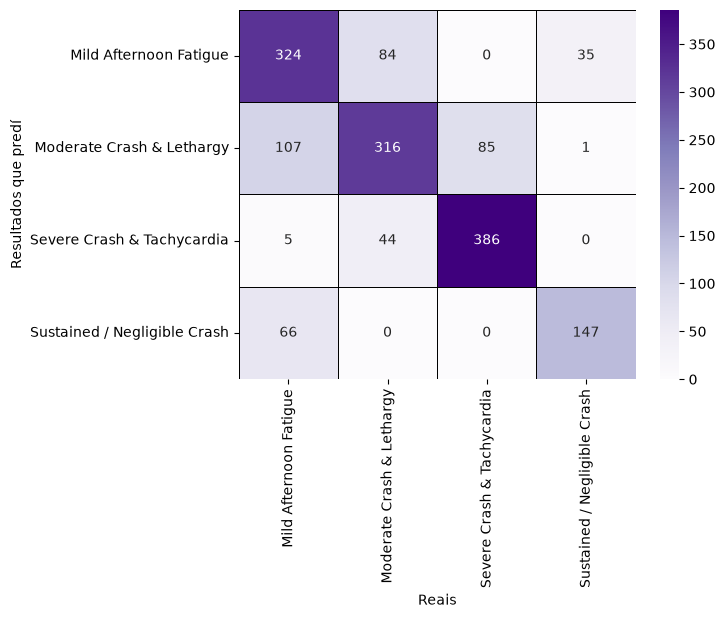

In [29]:
cm_3 = confusion_matrix(y2_test, y2_hat_test_1, labels=labels_1)

sns.heatmap(cm_3, cmap='Purples', annot=True, fmt='d', linewidths=0.6, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

#### 3.1.2 Estimación, training e resultados do Modelo RBF

In [30]:
param_rbf = {
    'C': [1, 10, 20, 50],
    'gamma': [0.005, 0.01, 0.05, 0.1]
}

grid_rbf = GridSearchCV(
    estimator = SVC(kernel='rbf'),
    param_grid = param_rbf,
    cv = 5,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_rbf.fit(x2_train_scaled, y2_train)
best_model_rbf = grid_rbf.best_estimator_

print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_rbf.best_score_:.4f}')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.8039


In [31]:
y2_hat_train_2 = best_model_rbf.predict(x2_train_scaled)
y2_hat_test_2 = best_model_rbf.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo RBF son {grid_rbf.best_params_}')
print(f'A exactitude de predición do modelo RBF no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_2):.4f}')
print(f'A exactitude de predición do modelo RBF no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_2):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_hat_test_2,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo RBF son {'C': 20, 'gamma': 0.01}
A exactitude de predición do modelo RBF no conxunto de adestramento é 0.8384
A exactitude de predición do modelo RBF no conxunto de teste é 0.7875

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.73      0.78      0.75       443
   Moderate Crash & Lethargy       0.75      0.77      0.76       509
  Severe Crash & Tachycardia       0.89      0.84      0.87       435
Sustained / Negligible Crash       0.82      0.74      0.78       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600



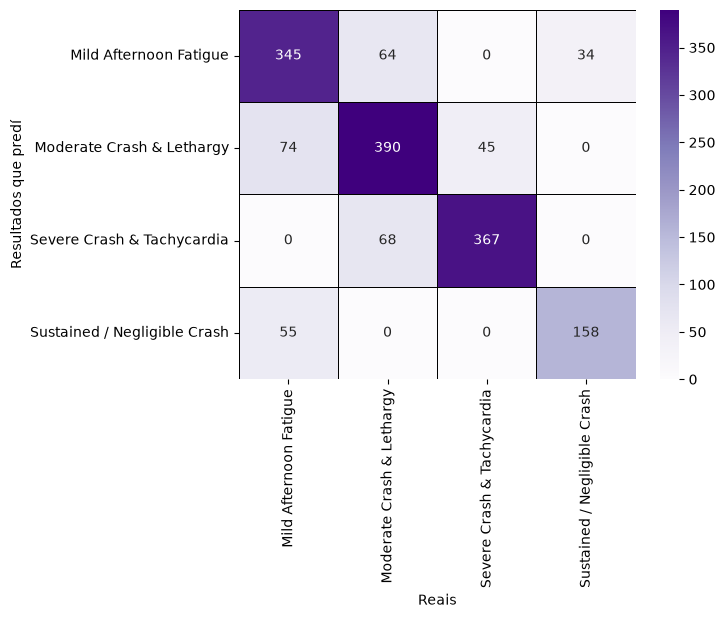

In [32]:
cm_4 = confusion_matrix(y2_test, y2_hat_test_2, labels=labels_1)

sns.heatmap(cm_4, cmap='Purples', annot=True, fmt='d', linewidths=0.6, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

#### 3.1.3 Estimación, training e resultados do Modelo RandomForest

Imos probar ademais tamén con outros modelos, neste caso tipo árbore. Por unha banda empregamos un sistema de árbores independentes `RandomForestClassifier()` e pola outra un sistema de árbores secuenciais `HistGradientBoostingClassifier`

**Caption.**     O tempo de compilado dos modelos tipo árbore é bastante extenso, teño un procesador bastante potente e aínda así tárdame ao redor 1 minuto cada un.

In [33]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

param_forest = {
    'n_estimators': [400, 500, 600],
    'max_depth': [None, 10, 20, 25],
    'min_samples_leaf': [1, 2, 3]
}

grid_forest = GridSearchCV(
    RandomForestClassifier(random_state=100),
    param_grid = param_forest,
    cv = 5,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_forest.fit(x2_train_scaled, y2_train)
best_model_forest = grid_forest.best_estimator_

print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_forest.best_score_:.4f}')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.7522


In [34]:
y2_hat_train_3 = best_model_forest.predict(x2_train_scaled)
y2_hat_test_3 = best_model_forest.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo RandomForestClassifier son {grid_forest.best_params_}')
print(f'A exactitude de predición do modelo RandomForestClassifier no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_3):.4f}')
print(f'A exactitude de predición do modelo RandomForestClassifier no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_3):.4f}\n')

print(
    classification_report(
        y1_test,
        y1_hat_test_2,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo RandomForestClassifier son {'max_depth': 25, 'min_samples_leaf': 1, 'n_estimators': 500}
A exactitude de predición do modelo RandomForestClassifier no conxunto de adestramento é 1.0000
A exactitude de predición do modelo RandomForestClassifier no conxunto de teste é 0.7600

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.90      0.94      0.92       443
   Moderate Crash & Lethargy       0.91      0.94      0.92       509
  Severe Crash & Tachycardia       0.96      0.92      0.94       435
Sustained / Negligible Crash       0.94      0.86      0.90       213

                    accuracy                           0.92      1600
                   macro avg       0.93      0.92      0.92      1600
                weighted avg       0.93      0.92      0.92      1600



As nosas árbores teñen un n bastante alto de estimadores (500) o que lle permite practicamente "memorizar" os resultados do entrenamento, de aí que a precisión á hora de predecilos sexa exacta e sen erros 

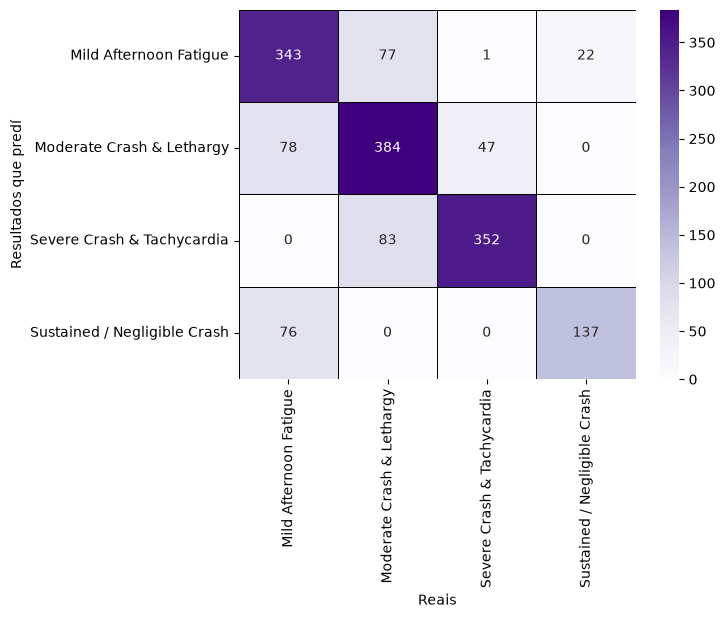

In [35]:
cm_5 = confusion_matrix(y2_test, y2_hat_test_3, labels=labels_1)

sns.heatmap(cm_5, cmap='Purples', annot=True, fmt='d', linewidths=0.5, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

#### 3.1.4 Estimación, training e resultados do Modelo HistGradientBoosting

In [36]:
param_boost = {
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 10],
    'max_iter': [100, 200, 500]
}

grid_boost = GridSearchCV(
    HistGradientBoostingClassifier(random_state=100),
    param_grid = param_boost,
    cv = 5,
    scoring = 'f1_macro',
    n_jobs = -1
)

grid_boost.fit(x2_train_scaled, y2_train)
best_model_boost = grid_boost.best_estimator_

print(f'O f1-macro medio das n validacións cruzadas cos mellores parámetros é {grid_boost.best_score_:.4f}')

O f1-macro medio das n validacións cruzadas cos mellores parámetros é 0.7866


In [37]:
y2_hat_train_4 = best_model_boost.predict(x2_train_scaled)
y2_hat_test_4 = best_model_boost.predict(x2_test_scaled)

print(f'Os mellores axustes para o modelo HistGradientBoosting son {grid_boost.best_params_}')
print(f'A exactitude de predición do modelo HistGradientBoosting no conxunto de adestramento é {accuracy_score(y2_train, y2_hat_train_4):.4f}')
print(f'A exactitude de predición do modelo HistGradientBoosting no conxunto de teste é {accuracy_score(y2_test, y2_hat_test_4):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_hat_test_4,
        target_names=labels_1
    )
)

Os mellores axustes para o modelo HistGradientBoosting son {'learning_rate': 0.05, 'max_depth': 3, 'max_iter': 500}
A exactitude de predición do modelo HistGradientBoosting no conxunto de adestramento é 0.9136
A exactitude de predición do modelo HistGradientBoosting no conxunto de teste é 0.7750

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.72      0.76      0.74       443
   Moderate Crash & Lethargy       0.74      0.75      0.75       509
  Severe Crash & Tachycardia       0.87      0.84      0.85       435
Sustained / Negligible Crash       0.80      0.72      0.76       213

                    accuracy                           0.78      1600
                   macro avg       0.78      0.77      0.77      1600
                weighted avg       0.78      0.78      0.78      1600



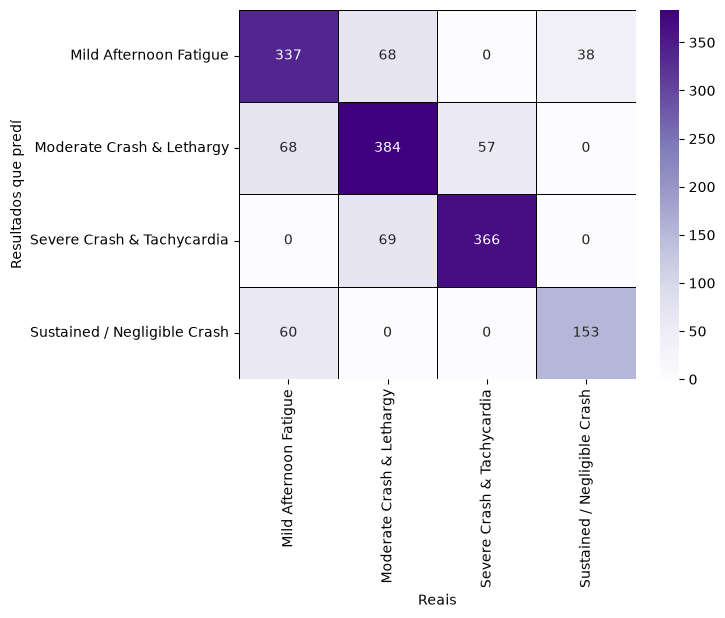

In [38]:
cm_6 = confusion_matrix(y2_test, y2_hat_test_4, labels=labels_1)

sns.heatmap(cm_6, cmap='Purples', annot=True, fmt='d', linewidths=0.6, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Resultados que predí')
plt.xlabel('Reais')
plt.show()

### 3.2 Conclusións

Primeiro fixemos os cálculos incluíndo a columna de score e obtivemos

In [39]:
print(f'Para o modelo linear obtivemos unha exactitude do {accuracy_score(y1_test, y1_hat_test_1)*100:.2f}% e para o RBF unha do {accuracy_score(y1_test, y1_hat_test_2)*100:.2f}%')
if accuracy_score(y1_test, y1_hat_test_1) > accuracy_score(y1_test, y1_hat_test_2):
    print('A pesar das limitacións dun modelo linear predice mellor que un gaussiano')
else:
    print('O modelo gaussiano predí mellor, como se esperaba, que o modelo linear')

Para o modelo linear obtivemos unha exactitude do 76.38% e para o RBF unha do 92.44%
O modelo gaussiano predí mellor, como se esperaba, que o modelo linear


Ambos modelos predicen moi ben o conxunto de teste. O linear, como é de esperar, é bastante limitado, pola contra o RBF cun score do 92% é algo extraordinario que se pode xustificar, como se dixo, pola alta correlación entre as columnas <<crash_risk_level>> e <<crash_severity_score>>.

En consecuencia volvemos a realizar os cálculos eliminando a columna <<crash_severity_score>> e para asegurar uns bos resultados optimizamos por validación cruzada os parámetros dos modelos. Os nosos resultados de predición sobre o conxunto de teste son

In [40]:
print(f'Para o modelo loxístico obtivemos unha exactitude do {accuracy_score(y2_test, y2_hat_test_1)*100:.2f}%, para o RBF unha do {accuracy_score(y2_test, y2_hat_test_2)*100:.2f}%, para o modelo RandomForest \nunha do {accuracy_score(y2_test, y2_hat_test_3)*100:.2f}% e para o modelo HistGradientBoosting é de {accuracy_score(y2_test, y2_hat_test_4)*100:.2f}%')

resultados = {
    'Loxístico': accuracy_score(y2_test, y2_hat_test_1),
    'RBF': accuracy_score(y2_test, y2_hat_test_2),
    'RandomForest': accuracy_score(y2_test, y2_hat_test_3),
    'HistGradientBoosting': accuracy_score(y2_test, y2_hat_test_4)
}

print(f'Todos os modelos teñen unha capacidade de predición semellante, o {max(resultados, key=resultados.get)} é lixeiramente mellor, superando incluso aos modelos de árbore.')

Para o modelo loxístico obtivemos unha exactitude do 73.31%, para o RBF unha do 78.75%, para o modelo RandomForest 
unha do 76.00% e para o modelo HistGradientBoosting é de 77.50%
Todos os modelos teñen unha capacidade de predición semellante, o RBF é lixeiramente mellor, superando incluso aos modelos de árbore.


### 3.3 Análise de regresións (Score)

O primeiro é definir as variables y coa columna <<crash_severity_score>>, que é numérica (float entre 0 e 10). Non fará falta definir x porque a x2 definida anteriormente é precisamente a que nos interesa.

In [41]:
# X é identico a x2_train_scaled, x2_test_scaled
y_score = Df['crash_severity_score']
y_score_train, y_score_test = y_score[:split], y_score[split:]

Imos tamén probar un par de modelos como fixemos até agora: un linear, un poly de grao 2, 3, 5 e 10 e finalmente un rbf. Aplicaremos tamén un proceso de cross validation de moi poucos n porque ten un custo computacional enorme (varios minutos).

### 3.3.1 Estimación, training e resultados do modelo SVR linear

In [ ]:
from sklearn.svm import SVR
from sklearn.model_selection import KFold
cv = KFold(n_splits=2, shuffle=True, random_state=100)

param_svr_lin = {'C': [1, 10, 100]}

grid_svr_lin = GridSearchCV(
    estimator = SVR(kernel='linear'),
    param_grid = param_svr_lin,
    cv = 5,
    scoring = 'r2', # como estamos avaliando un axuste a unha función interésanos o Pearson
    n_jobs = -1
)

grid_svr_lin.fit(x2_train_scaled, y_score_train)
best_model_svr_lin = grid_svr_lin.best_estimator_

print(f'Das n validacións cruzadas o mellor r2 é {grid_svr_lin.best_score_:.4f}, cuxos parámetros óptimos son {grid_svr_lin.best_params_}')

y_score_hat_train_lin = best_model_svr_lin.predict(x2_train_scaled)
y_score_hat_test_lin = best_model_svr_lin.predict(x2_test_scaled)
print(f'O r2 no mellor modelo linear no conxunto de adestramento é {r2_score(y_score_train, y_score_hat_train_lin):.4f}')
print(f'O r2 no mellor modelo linear no conxunto de teste é {r2_score(y_score_test, y_score_hat_test_lin):.4f}\n')

Das n validacións cruzadas o mellor r2 é 0.8913, cuxos parámetros óptimos son {'C': 1}
O r2 no modelo linear no conxunto de adestramento é 0.8924
O r2 no modelo linear no conxunto de teste é 0.8889



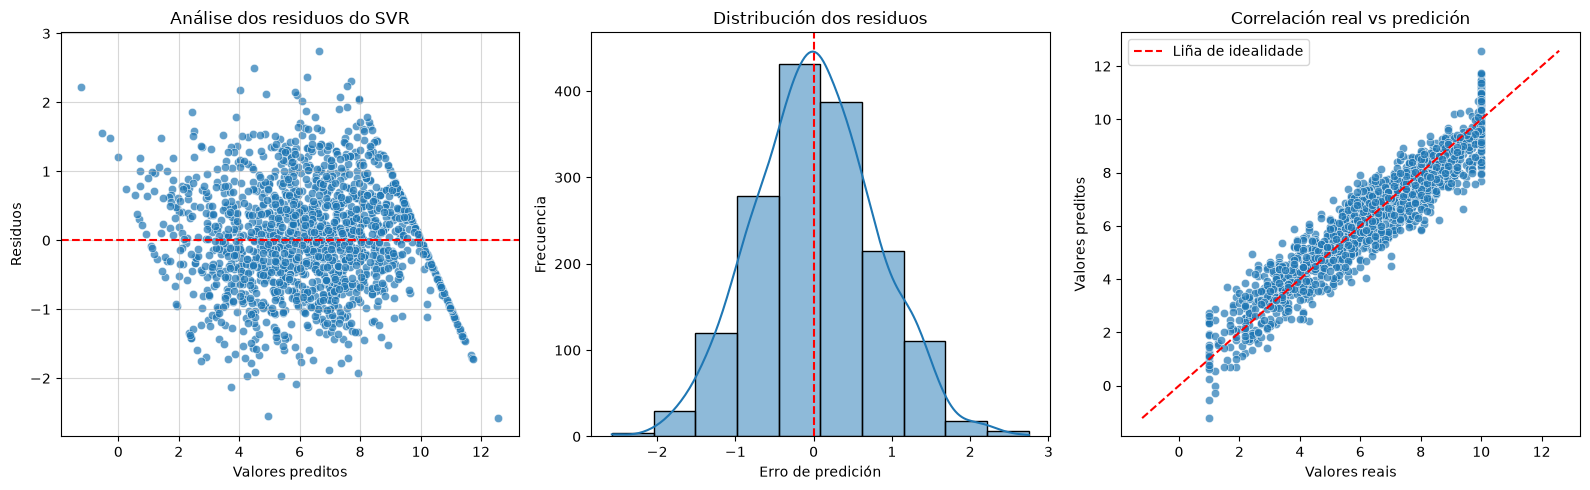

In [ ]:
fig, axs = plt.subplots(1,3, figsize=(16, 5))  

residuos = y_score_test - y_score_hat_test_lin

# 1. Gráfico de residuos
sns.scatterplot(x = y_score_hat_test_lin,y = residuos, alpha=0.8, ax=axs[0])
axs[0].axhline(0, color='red', linestyle='--')
axs[0].set_xlabel("Valores preditos")
axs[0].set_ylabel("Residuos")
axs[0].set_title("Análise dos residuos en Linear")
axs[0].grid(alpha=0.6)

# 2. Histograma dos residuos
sns.histplot(residuos, kde=True, bins=10, ax=axs[1])
axs[1].axvline(0, color='red', linestyle='--')
axs[1].set_xlabel("Erro de predición")
axs[1].set_ylabel("Frecuencia")
axs[1].set_title("Distribución dos residuos en Linear")

# 3. Valores reais vs preditos
sns.scatterplot(x = y_score_test, y = y_score_hat_test_lin, alpha = 0.8, ax = axs[2])

limites = [
    min(y_score_test.min(), y_score_hat_test_lin.min()),
    max(y_score_test.max(), y_score_hat_test_lin.max())
]

axs[2].plot(limites, limites, 'r--', label='Liña de idealidade')
axs[2].set_xlabel('Valores reais')
axs[2].set_ylabel('Valores preditos')
axs[2].set_title('Correlación real vs predición en Linear')
axs[2].grid(alpha=0.6)
axs[2].legend()

plt.tight_layout()
plt.show()

### 3.3.2 Estimación, training e resultados do modelo SVR polinómico

In [59]:
param_svr_poly = {
    'C': [1, 10, 100,],
    'gamma': ['auto','scale'],
    'degree': [2, 3, 5, 10],
    'epsilon': [0.2, 0.1],
    'coef0': [0, 1]
}

grid_svr_poly = GridSearchCV(
    estimator = SVR(kernel='poly'),
    param_grid = param_svr_poly,
    cv = cv,
    scoring = 'r2', # ver isto
    n_jobs = -1
)

grid_svr_poly.fit(x2_train_scaled, y_score_train)
best_model_svr_poly = grid_svr_poly.best_estimator_

print(f'Das n validacións cruzadas o mellor r2 é {grid_svr_poly.best_score_:.4f}, cuxos parámetros óptimos son {grid_svr_poly.best_params_}')

y_score_hat_train_poly = best_model_svr_poly.predict(x2_train_scaled)
y_score_hat_test_poly = best_model_svr_poly.predict(x2_test_scaled)
print(f'O r2 no mellor modelo polinómico no conxunto de adestramento é {r2_score(y_score_train, y_score_hat_train_poly):.4f}')
print(f'O r2 no mellor modelo polinómico no conxunto de teste é {r2_score(y_score_test, y_score_hat_test_poly):.4f}\n')

Das n validacións cruzadas o mellor r2 é 0.9103, cuxos parámetros óptimos son {'C': 1, 'coef0': 1, 'degree': 3, 'epsilon': 0.2, 'gamma': 'scale'}
O r2 no modelo polinómico no conxunto de adestramento é 0.9336
O r2 no modelo polinómico no conxunto de teste é 0.9173



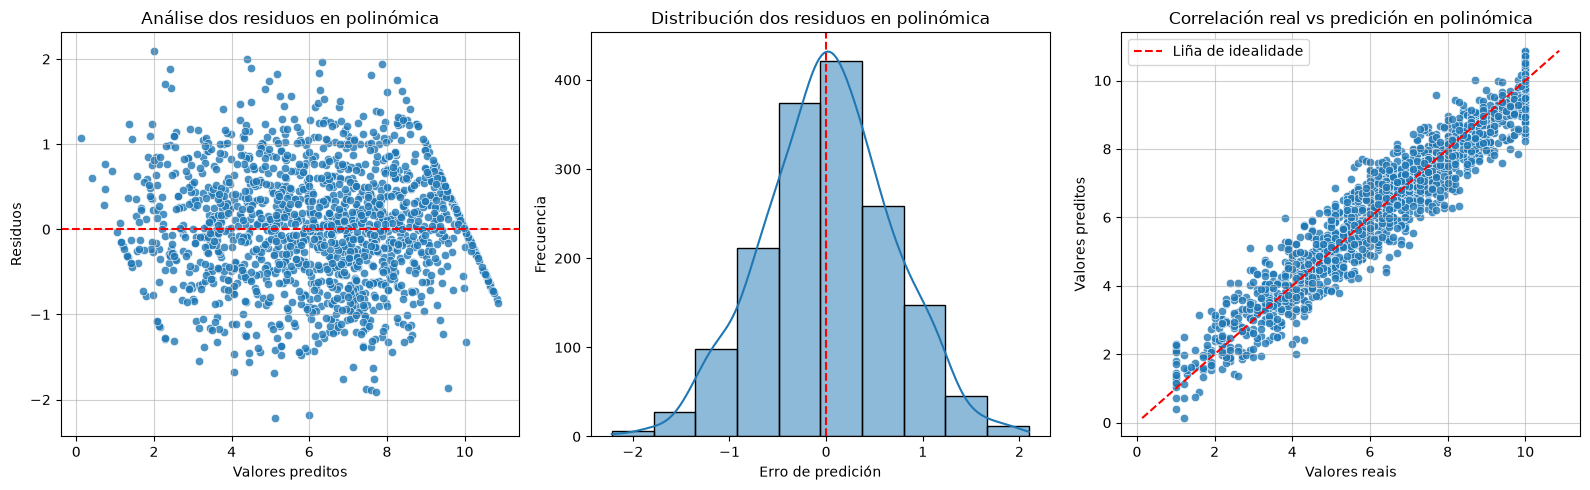

In [60]:
fig, axs = plt.subplots(1,3, figsize=(16, 5))  

residuos = y_score_test - y_score_hat_test_poly

# 1. Gráfico de residuos
sns.scatterplot(x = y_score_hat_test_poly, y = residuos, alpha=0.8, ax=axs[0])
axs[0].axhline(0, color='red', linestyle='--')
axs[0].set_xlabel("Valores preditos")
axs[0].set_ylabel("Residuos")
axs[0].set_title("Análise dos residuos en polinómica")
axs[0].grid(alpha=0.6)

# 2. Histograma dos residuos
sns.histplot(residuos, kde=True, bins=10, ax=axs[1])
axs[1].axvline(0, color='red', linestyle='--')
axs[1].set_xlabel("Erro de predición")
axs[1].set_ylabel("Frecuencia")
axs[1].set_title("Distribución dos residuos en polinómica")

# 3. Valores reais vs preditos
sns.scatterplot(x = y_score_test, y = y_score_hat_test_poly, alpha=0.8, ax = axs[2])

limites = [
    min(y_score_test.min(), y_score_hat_test_poly.min()),
    max(y_score_test.max(), y_score_hat_test_poly.max())
]

axs[2].plot(limites, limites, 'r--', label='Liña de idealidade')
axs[2].set_xlabel('Valores reais')
axs[2].set_ylabel('Valores preditos')
axs[2].set_title('Correlación real vs predición en polinómica')
axs[2].grid(alpha=0.6)
axs[2].legend()

plt.tight_layout()
plt.show()

### 3.3.3 Estimación, training e resultados do modelo SVR RBF

In [61]:
param_svr_rbf = {
    'C': [1, 10, 100],
    'gamma': ['auto','scale'],
    'epsilon': [0.1, 0.2]
}

grid_svr_rbf = GridSearchCV(
    estimator = SVR(kernel='rbf'),
    param_grid = param_svr_rbf,
    cv = cv,
    scoring = 'r2', 
    n_jobs = -1 
)

grid_svr_rbf.fit(x2_train_scaled, y_score_train)
best_model_svrrbf = grid_svr_rbf.best_estimator_


print(f'Das n validacións cruzadas o mellor r2 é {grid_svr_rbf.best_score_:.4f}, cuxos parámetros óptimos son {grid_svr_rbf.best_params_}')

y_score_hat_train_rbf = best_model_svrrbf.predict(x2_train_scaled)
y_score_hat_test_rbf = best_model_svrrbf.predict(x2_test_scaled)
print(f'O r2 no mellor modelo RBF no conxunto de adestramento é {r2_score(y_score_train, y_score_hat_train_rbf):.4f}')
print(f'O r2 no mellor modelo RBF no conxunto de teste é {r2_score(y_score_test, y_score_hat_test_rbf):.4f}\n')

Das n validacións cruzadas o mellor r2 é 0.9041, cuxos parámetros óptimos son {'C': 1, 'epsilon': 0.2, 'gamma': 'auto'}
O r2 no mellor modelo RBF no conxunto de adestramento é 0.9306
O r2 no mellor modelo RBF no conxunto de teste é 0.9147



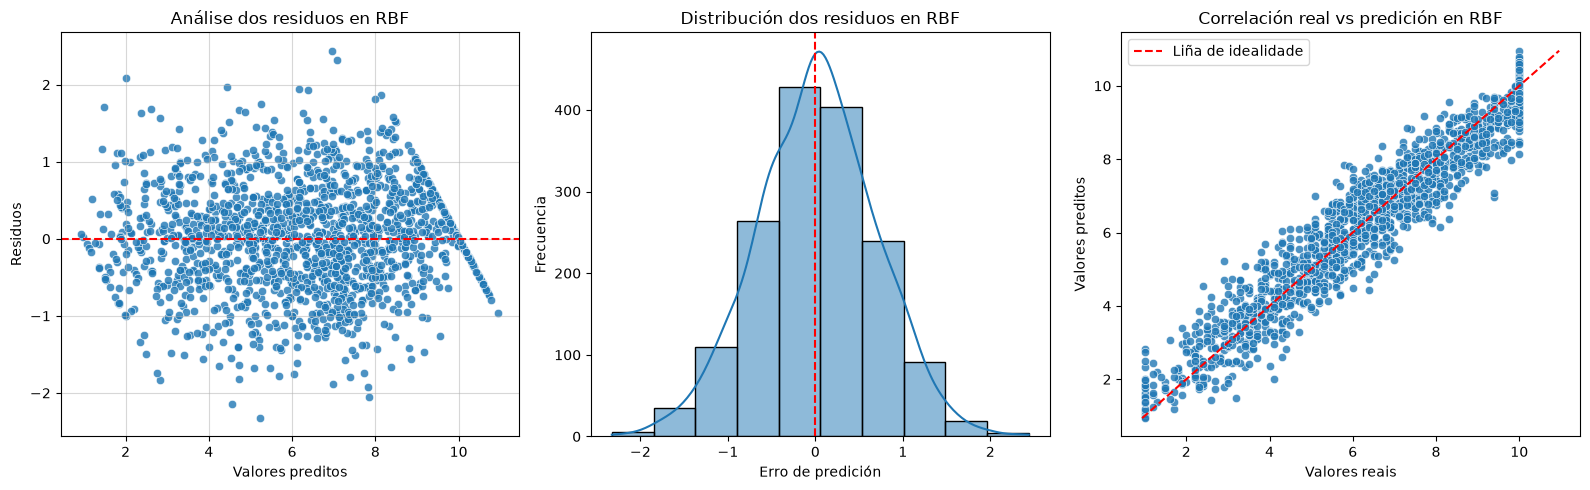

In [62]:
fig, axs = plt.subplots(1,3, figsize=(16, 5))  

residuos = y_score_test - y_score_hat_test_rbf

# 1. Gráfico de residuos
sns.scatterplot(x = y_score_hat_test_rbf, y = residuos, alpha=0.8, ax=axs[0])
axs[0].axhline(0, color='red', linestyle='--')
axs[0].set_xlabel("Valores preditos")
axs[0].set_ylabel("Residuos")
axs[0].set_title("Análise dos residuos en RBF")
axs[0].grid(alpha=0.5)

# 2. Histograma dos residuos
sns.histplot(residuos, kde=True, bins=10, ax=axs[1])
axs[1].axvline(0, color='red', linestyle='--')
axs[1].set_xlabel("Erro de predición")
axs[1].set_ylabel("Frecuencia")
axs[1].set_title("Distribución dos residuos en RBF")

# 3. Valores reais vs preditos
sns.scatterplot(x = y_score_test, y = y_score_hat_test_rbf, alpha = 0.8, ax = axs[2])

limites = [
    min(y_score_test.min(), y_score_hat_test_rbf.min()),
    max(y_score_test.max(), y_score_hat_test_rbf.max())
]

axs[2].plot(limites, limites, 'r--', label='Liña de idealidade')
axs[2].set_xlabel('Valores reais')
axs[2].set_ylabel('Valores preditos')
axs[2].set_title('Correlación real vs predición en RBF')
axs[2].legend()

plt.tight_layout()
plt.show()

### 3.3.4 Conclusións das regresións SVR

## 4. Análise con redes neuronais

Nesta sección probamos de novo a predicir os valores de <<crash_risk_level>> co conxunto de datos sen sesgo, pero esta vez probamos a modelizar unha rede neuronal. Empregamos o paquete keras co lanzador de tensorflow e creamos varios modelos basados en Sequential, conexións neuronais lineares, e como o noso análise é basicamente numérico só temos que usar capas tipo Dense() (para texto, imaxes, audio, etc débense empregar redes convulacionais ou ) e capas tipo Dropout() para evitar o overfitting. Empezamos por un modelo moi básico e o melloramos engadindo unha capa de profundida e usando funcións de activación máis suaves para reducir o ruído no loss e ademais impoñemos unha penalización aos pesos grandes (L2) nestas funcións para evitar que aparezan diverxencias. Este modelo xa funcionaría moi ben, pero imos un paso máis alá; empregamos `keras_tuner` que é un análogo á validación cruzada para neuronas e probamos distintas funcións de activación con distintos parámetros (learning_rate, L2, batch_size, número de neuronas) e con distintos optimizadores (en xeral podemos descartar todos aquelos que integren momento (Adam, Nadam, AdamW), incluso con nesterov, porque aparecen diverxencias moi significativas no loss e os de entreno e validación independínzanse), deixámolo calcular por moitas horas e aínda que os resultados non son nada concluíntes atopamos unha certa tendencia cara cales funcións e parámetros parecen mellores.

Consultar `memoria_traballo.pdf` para máis información sobre a elección dos modelos.

O primeiro que hai que facer é transformar os nosos y'es de str a vectores numéricos dalgunha forma, sklearn ten unha boa opción para facer esta transformación de xeito que as redes neuronais poidan traballar e non perdamos información. Unha consecuencia disto é que debemos ter 4 parámetros categoriales de saída axustados pola rede--> a capa de saída debe ter 4 units e operar coa función softmax.

In [62]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

y2_train_enc = le.fit_transform(y2_train)
y2_test_enc = le.transform(y2_test)

Definimos os tres devanditos modelos

In [ ]:
import tensorflow as tf
tf.keras.utils.set_random_seed(100)

from keras import layers
from keras.models import Sequential
from keras.regularizers import L1L2, L2, L1
from keras.optimizers import SGD, Adam, Nadam, AdamW
from keras.optimizers.schedules import ExponentialDecay

# initial_ler = 0.02
# lr_exp = ExponentialDecay(
#     initial_ler, decay_steps=1000, decay_rate=0.9, staircase=True
# )

def modelo_simple(data): # x2_train_scaled

    model = Sequential([
        layers.Input(shape=(data.shape[1],)),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.1),
        layers.Dense(16, activation='relu'),
        layers.Dense(4, activation='softmax')
        ])

    model.compile(optimizer = SGD(learning_rate = 0.0009
                ), loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])  # 90 iteracións son suficientes

    return model

def modelo_mellorado(data): # x2_train_scaled

    model = Sequential([
        layers.Input(shape=(data.shape[1],)),
        layers.Dense(64, activation='celu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
        layers.Dropout(0.1),
        layers.Dense(32, activation='celu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
        layers.Dense(16, activation='celu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
        layers.Dense(4, activation='softmax')
    ])

    model.compile(optimizer = SGD(learning_rate = 0.001
                ), loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])  

    return model

def modelo_optimizado(data): # Aínda que o modelo pareza considerablemente máis custoso computacionalmente que os anteriores, este permitiranos conseguir
    # resultados moi semellantes a modelo_mellorado con moitas menos iteracións (epochs = 60 ou 70) durante o entrenamento. Se poñemos moitas iteracións no modelo
    # mellorado podemos decatarnos que entre as 50 e 150 iteracións hai un val de precisión e temos que superar ese límite de 150 para predicións estables. No entanto, 
    # este modelo optimizado permite chegar un máximo de predición semellante que é basicamente constante despois das ~75 iteracións reducindo así moitimo o tempo de compilación

    model = Sequential([
        layers.Input(shape=(data.shape[1],)),
        layers.Dense(128, activation='silu', kernel_initializer='glorot_uniform' , kernel_regularizer= L1L2(l1 = 0.0002, l2 = 0.01)), # silu parece mellorar un pelin a puntuación
        layers.Dropout(0.1),
        layers.Dense(16, activation='celu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
        layers.Dense(40, activation='celu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)),
        layers.Dropout(0.1),
        layers.Dense(16, activation='relu', kernel_initializer='he_normal', kernel_regularizer= L2(0.01)), # probo entre relu e celu
        layers.Dense(4, activation='softmax')
        ])

    model.compile(optimizer = SGD(learning_rate = 0.001
                ), loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])  

    return model


modelo_simple(x2_train_scaled).summary()
modelo_mellorado(x2_train_scaled).summary()
modelo_optimizado(x2_train_scaled).summary()

Model: "sequential_27"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_110 (Dense)               │ (None, 32)             │           736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_37 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_111 (Dense)               │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_112 (Dense)               │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,332 (5.20 KB)

 Trainable params: 1,332 (5.20 KB)

 Non-trainable params: 0 (0.00 B)

Model: "sequential_28"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_117 (Dense)               │ (None, 128)            │         2,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_118 (Dense)               │ (None, 16)             │         2,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_119 (Dense)               │ (None, 40)             │           680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_120 (Dense)               │ (None, 16)             │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_121 (Dense)               │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,412 (25.05 KB)

 Trainable params: 6,412 (25.05 KB)

 Non-trainable params: 0 (0.00 B)

Toca entrenar as nosas redes neuronais, como entrenar 3 redes á vez leva un tempo bastante considerable podemos simplemente comentar aquelas que non nos interesen, deixamos só o entrenamento do modelo optimizado que será da que consideraremos resultados perdictivos

In [1]:
# modelo1 = modelo_simple(x2_train_scaled)
# cerebro_simple = modelo1.fit(
#     x2_train_scaled,
#     y2_train_enc,
#     epochs=70,
#     batch_size=8,
#     validation_data = (x2_test_scaled,y2_test_enc)
# )

# modelo2 = modelo_mellorado(x2_train_scaled)
# cerebro_mellorado = modelo2.fit(
#     x2_train_scaled,
#     y2_train_enc,
#     epochs=70,
#     batch_size=8,
#     validation_data = (x2_test_scaled,y2_test_enc)
# )

modelo3 = modelo_optimizado(x2_train_scaled)
cerebro_optimizado = modelo3.fit(
    x2_train_scaled,
    y2_train_enc,
    epochs=70,
    batch_size=8,
    validation_data = (x2_test_scaled,y2_test_enc)
)

# e se probo a facer unha nova subdivisión con validation_split? Realmente non sei o que sería correcto entre as dúas opcións.

NameError: name 'modelo_optimizado' is not defined

o valor final da precisión no entrenamento da rede simple é  0.7865625023841858
o valor final da precisión no teste da rede simple é  0.7981250286102295
o valor final do loss no entrenamento da rede simple é  0.4803984463214874
o valor final do loss no teste da rede simple é  0.4704945385456085 

o valor final da precisión no entrenamento da rede mellorada é  0.80078125
o valor final da precisión no teste da rede mellorada é  0.7943750023841858
o valor final do loss no entrenamento da rede mellorada é  0.5474504232406616
o valor final do loss no teste da rede mellorada é  0.5542457699775696 

o valor final da precisión no entrenamento da rede optimizada é  0.7989062666893005
o valor final da precisión no teste da rede optimizada é  0.796875
o valor final do loss no entrenamento da rede optimizada é  0.8060024380683899
o valor final do loss no teste da rede optimizada é  0.8014047741889954 



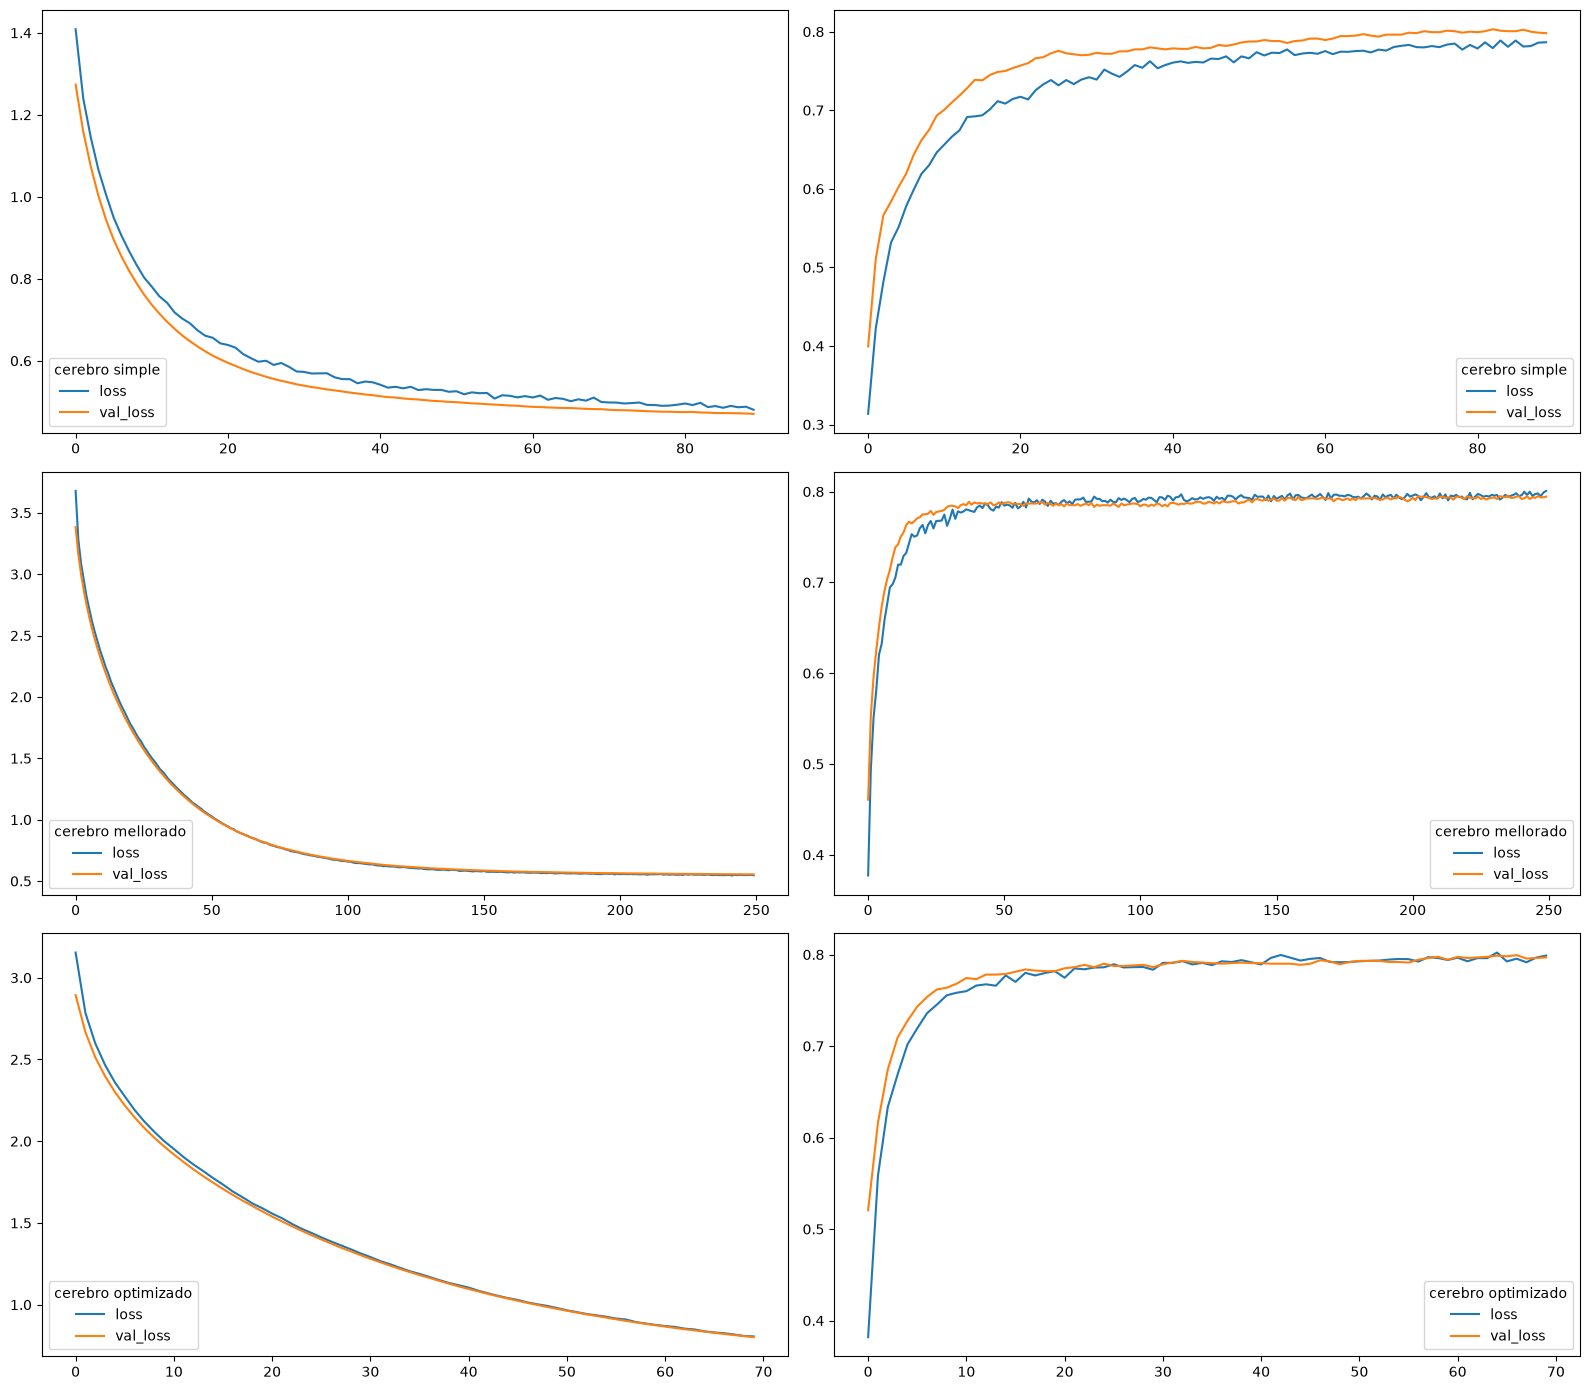

In [96]:
# poñer as gráficas e tal
print('o valor final da precisión no entrenamento da rede simple é ', cerebro_simple.history['accuracy'][-1])
print('o valor final da precisión no teste da rede simple é ', cerebro_simple.history['val_accuracy'][-1])
print('o valor final do loss no entrenamento da rede simple é ', cerebro_simple.history['loss'][-1])
print('o valor final do loss no teste da rede simple é ', cerebro_simple.history['val_loss'][-1], '\n')

print('o valor final da precisión no entrenamento da rede mellorada é ', cerebro_mellorado.history['accuracy'][-1])
print('o valor final da precisión no teste da rede mellorada é ', cerebro_mellorado.history['val_accuracy'][-1])
print('o valor final do loss no entrenamento da rede mellorada é ', cerebro_mellorado.history['loss'][-1])
print('o valor final do loss no teste da rede mellorada é ', cerebro_mellorado.history['val_loss'][-1], '\n')

print('o valor final da precisión no entrenamento da rede optimizada é ', cerebro_optimizado.history['accuracy'][-1])
print('o valor final da precisión no teste da rede optimizada é ', cerebro_optimizado.history['val_accuracy'][-1])
print('o valor final do loss no entrenamento da rede optimizada é ', cerebro_optimizado.history['loss'][-1])
print('o valor final do loss no teste da rede optimizada é ', cerebro_optimizado.history['val_loss'][-1], '\n')


fig, axs = plt.subplots(3,2, figsize=(16, 14))  

axs[0,0].plot(cerebro_simple.history['loss'], label = 'loss')
axs[0,0].plot(cerebro_simple.history['val_loss'], label =  'val_loss')
axs[0,0].legend(title=f'cerebro simple', loc='lower left')
axs[0,1].plot(cerebro_simple.history['accuracy'], label = 'loss')
axs[0,1].plot(cerebro_simple.history['val_accuracy'], label =  'val_loss')
axs[0,1].legend(title=f'cerebro simple', loc='lower right')

axs[1,0].plot(cerebro_mellorado.history['loss'], label = 'loss')
axs[1,0].plot(cerebro_mellorado.history['val_loss'], label =  'val_loss')
axs[1,0].legend(title=f'cerebro mellorado', loc='lower left')
axs[1,1].plot(cerebro_mellorado.history['accuracy'], label = 'loss')
axs[1,1].plot(cerebro_mellorado.history['val_accuracy'], label =  'val_loss')
axs[1,1].legend(title=f'cerebro mellorado', loc='lower right')

axs[2,0].plot(cerebro_optimizado.history['loss'], label = 'loss')
axs[2,0].plot(cerebro_optimizado.history['val_loss'], label =  'val_loss')
axs[2,0].legend(title=f'cerebro optimizado', loc='lower left')
axs[2,1].plot(cerebro_optimizado.history['accuracy'], label = 'loss')
axs[2,1].plot(cerebro_optimizado.history['val_accuracy'], label =  'val_loss')
axs[2,1].legend(title=f'cerebro optimizado', loc='lower right')

plt.tight_layout()
fig.show()

Se se entrenaron os 3 modelos verás bastantes outputs e aínda que as tres sexan máis ou menos boas empregaremos só a mellor para dar resultados, ou sexa, consideramos só `modelo_optimizado`.

In [86]:
y2_neuron_train_class = np.argmax(modelo3.predict(x2_train_scaled), axis=1)
y2_neuron_train_labels = le.inverse_transform(y2_neuron_train_class)
y2_neuron_test_class = np.argmax(modelo3.predict(x2_test_scaled), axis=1)
y2_neuron_test_labels = le.inverse_transform(y2_neuron_test_class)

print(f'A exactitude de predición da rede neuronal no conxunto de adestramento é {accuracy_score(y2_train, y2_neuron_train_labels):.4f}')
print(f'A exactitude de predición da rede neuronal no conxunto de teste é {accuracy_score(y2_test, y2_neuron_test_labels):.4f}\n')

print(
    classification_report(
        y2_test,
        y2_neuron_test_labels,
        target_names=labels_1
    )
)

200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
A exactitude de predición da rede neuronal no conxunto de adestramento é 0.8064
A exactitude de predición da rede neuronal no conxunto de teste é 0.7875

                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.72      0.80      0.76       443
   Moderate Crash & Lethargy       0.75      0.76      0.76       509
  Severe Crash & Tachycardia       0.89      0.85      0.87       435
Sustained / Negligible Crash       0.84      0.70      0.76       213

                    accuracy                           0.79      1600
                   macro avg       0.80      0.78      0.79      1600
                weighted avg       0.79      0.79      0.79      1600



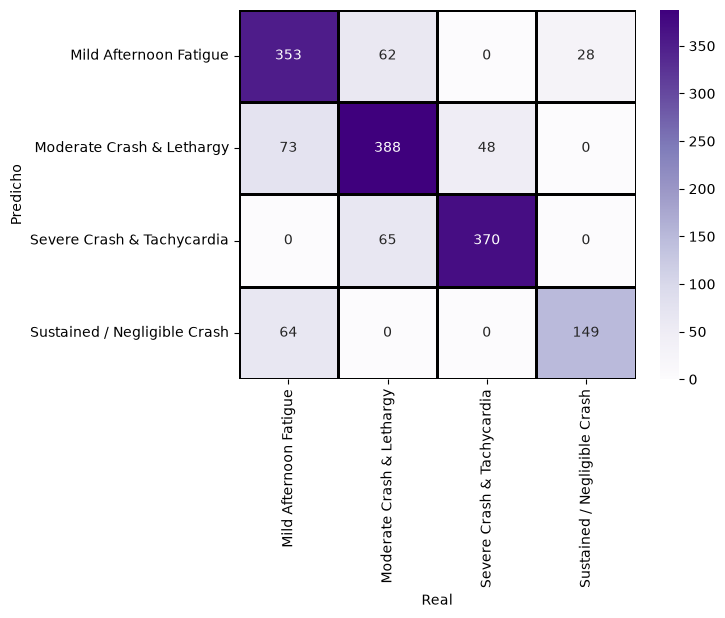

In [87]:
cm_rede = confusion_matrix(y2_test, y2_neuron_test_labels, labels=labels_1)

sns.heatmap(cm_rede, cmap='Purples', annot=True, fmt='d', linewidths=1, linecolor='black', xticklabels=labels_1, yticklabels=labels_1)
plt.ylabel('Predicho')
plt.xlabel('Real')
plt.show()

falar das conclusións

## 5. Conclusións finais

moitas cousas
comparar redes con sklearn

## Apéndice Cross Validation en redes neuronais

**CAPTION** Non correr estas celas é un total de ~7h. Déixoas comentadas por se acaso.

In [ ]:
# import keras_tuner as kt

# def build_model(hp):

#     l2 = hp.Choice("l2", [0.0, 0.05, 0.01, 0.005, 0.001])

#     model = Sequential([
#         layers.Input(shape=(x2_train_scaled.shape[1],)),

#         layers.Dense(
#             hp.Int("n1", 16, 128, step=16),
#             activation='relu',
#             kernel_initializer='he_normal',
#             kernel_regularizer=L2(l2)
#         ),

#         layers.Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2])),

#         layers.Dense(
#             hp.Int("n2", 8, 64, step=8),
#             activation='relu', kernel_initializer='he_normal', kernel_regularizer = L2(l2)
#         ),

#         layers.Dense(16, activation='relu', 
#                 kernel_initializer='he_normal', 
#                 kernel_regularizer= L2(l2)
#             ),

#         layers.Dense(4, activation='softmax')
#     ])

#     model.compile(
#         optimizer=SGD(
#             learning_rate=hp.Choice("lr", [0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001, 0.00001])
#         ),
#         loss='sparse_categorical_crossentropy',
#         metrics=['accuracy']
#     )

#     return model

# os.makedirs("axuste_keras", exist_ok=True)

# tuner = kt.RandomSearch(
#     build_model,
#     objective='val_accuracy',
#     max_trials=50,
#     executions_per_trial=3,
#     directory="/axuste_keras",
#     project_name="modelo1",
#     overwrite=True
# )

# tuner.search(
#     x2_train_scaled,
#     y2_train_enc,
#     validation_data=(x2_test_scaled, y2_test_enc),
#     epochs=60,
#     batch_size=10
# )



Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
0.005             |0.005             |l2
128               |128               |n1
0.1               |0.1               |dropout
8                 |8                 |n2
0.0005            |0.0005            |lr

Epoch 1/60
640/640 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.3033 - loss: 3.1285 - val_accuracy: 0.3425 - val_loss: 2.9316
Epoch 2/60
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3411 - loss: 2.9248 - val_accuracy: 0.3650 - val_loss: 2.8701
Epoch 3/60
640/640 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.3652 - loss: 2.8714 - val_accuracy: 0.4081 - val_loss: 2.8265
Epoch 4/60
 71/640 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.4014 - loss: 2.8471

KeyboardInterrupt: 

Epoch 1/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8037 - loss: 0.6388 - val_accuracy: 0.7931 - val_loss: 0.6459
Epoch 2/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7983 - loss: 0.6223 - val_accuracy: 0.7956 - val_loss: 0.6270
Epoch 3/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8016 - loss: 0.6067 - val_accuracy: 0.7919 - val_loss: 0.6174
Epoch 4/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8022 - loss: 0.5923 - val_accuracy: 0.7869 - val_loss: 0.6042
Epoch 5/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8037 - loss: 0.5842 - val_accuracy: 0.7956 - val_loss: 0.5909
Epoch 6/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8012 - loss: 0.5748 - val_accuracy: 0.7937 - val_loss: 0.5803
Epoch 7/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8031 - loss: 0.5633 - val_accuracy: 0.7919 - val_loss: 0.5782
Epoch 8/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8067 - loss: 0.5563 - val_accuracy: 0.

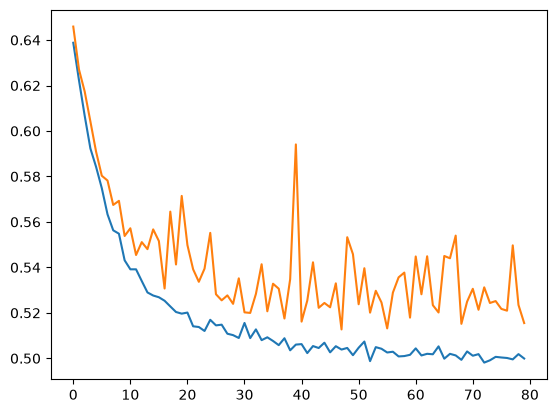

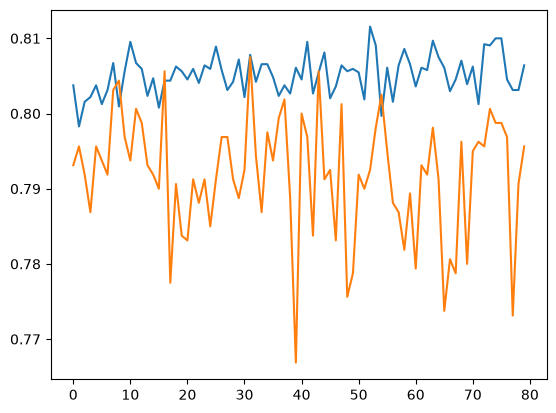

In [ ]:
# best_model = tuner.get_best_models(1)[0]
# cerebro = best_model.fit(
#     x2_train_scaled,
#     y2_train_enc,
#     validation_data=(x2_test_scaled, y2_test_enc),
#     epochs=80,
#     batch_size=8
# )

# plt.plot(cerebro.history['loss'])
# plt.plot(cerebro.history['val_loss'])

# print(cerebro.history['accuracy'][-1])
# print(cerebro.history['val_accuracy'][-1])
# print(cerebro.history['loss'][-1])
# print(cerebro.history['val_loss'][-1])

# plt.figure()

# plt.plot(cerebro.history['accuracy'])
# plt.plot(cerebro.history['val_accuracy'])

In [ ]:
# def build_model_modified(hp):
#     lr1 = hp.Choice("l1", [0.0, 0.01, 0.001, 0.0001])
#     lr2 = hp.Choice("l2", [0.0, 0.05, 0.01, 0.005, 0.001])

#     model = Sequential([
#         layers.Input(shape=(x2_train_scaled.shape[1],)),

#         layers.Dense(hp.Int("n1", 32, 256, step=32), 
#                      activation='softplus', kernel_initializer='glorot_uniform' , 
#                      kernel_regularizer= L1L2(l1 = lr1, l2 = lr2)),
#         layers.Dense(hp.Int("n2", 8, 64, step=8), 
#                      activation='elu', kernel_initializer='he_normal', 
#                      kernel_regularizer= L2(lr2)),
#         layers.Dense(hp.Int("n3", 16, 64, step=8), 
#                      activation='leaky_relu', kernel_initializer='he_normal', 
#                      kernel_regularizer= L2(lr2)),
#         layers.Dense(hp.Int("n4", 12, 32, step=4), 
#                      activation='leaky_relu', kernel_initializer='he_normal', 
#                      kernel_regularizer= L2(lr2)),
        
#         layers.Dense(4, activation='softmax')
#     ])

#     model.compile(
#         optimizer=Adam(
#             learning_rate=hp.Choice("lr", [0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001])
#         ),
#         loss='sparse_categorical_crossentropy',
#         metrics=['accuracy']
#     )

#     return model

# os.makedirs("axuste_keras", exist_ok=True)

# tuner = kt.RandomSearch(
#     build_model_modified,
#     objective='val_accuracy',
#     max_trials=50,
#     executions_per_trial=3,
#     directory="/axuste_keras",
#     project_name="modelo2",
#     overwrite=True
# )

# tuner.search(
#     x2_train_scaled,
#     y2_train_enc,
#     validation_data=(x2_test_scaled, y2_test_enc),
#     epochs=60,
#     batch_size=8
# )

Trial 50 Complete [00h 05m 24s]
val_accuracy: 0.7981250087420145

Best val_accuracy So Far: 0.8079166611035665
Total elapsed time: 04h 26m 16s


Epoch 1/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7998 - loss: 0.4921 - val_accuracy: 0.7856 - val_loss: 0.5011
Epoch 2/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7994 - loss: 0.4835 - val_accuracy: 0.7875 - val_loss: 0.5199
Epoch 3/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7975 - loss: 0.4887 - val_accuracy: 0.7944 - val_loss: 0.4926
Epoch 4/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7994 - loss: 0.4866 - val_accuracy: 0.7956 - val_loss: 0.5030
Epoch 5/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7972 - loss: 0.4862 - val_accuracy: 0.7894 - val_loss: 0.5057
Epoch 6/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7933 - loss: 0.4887 - val_accuracy: 0.7706 - val_loss: 0.5375
Epoch 7/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7991 - loss: 0.4854 - val_accuracy: 0.7894 - val_loss: 0.5047
Epoch 8/80
800/800 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.7972 - loss: 0.4879 - val_accuracy: 0.

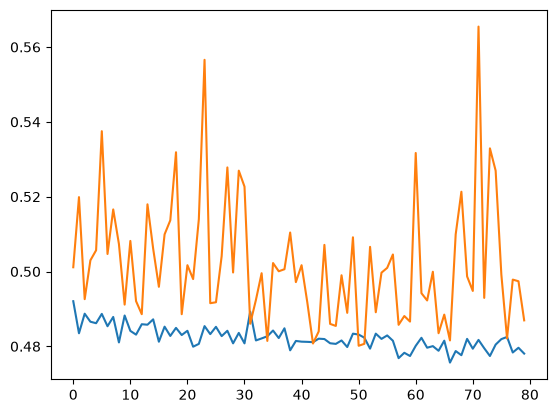

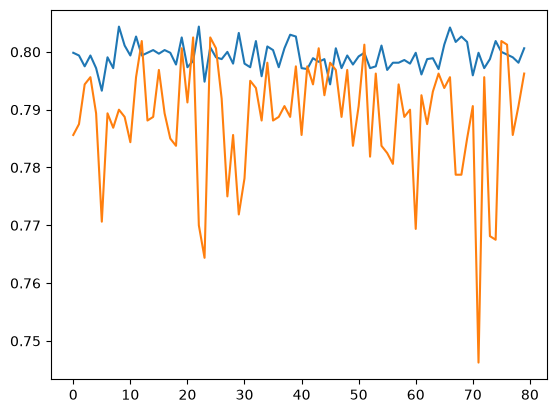

In [ ]:
# best_model = tuner.get_best_models(1)[0]
# cerebro = best_model.fit(
#     x2_train_scaled,
#     y2_train_enc,
#     validation_data=(x2_test_scaled, y2_test_enc),
#     epochs=80,
#     batch_size=8
# )

# plt.plot(cerebro.history['loss'])
# plt.plot(cerebro.history['val_loss'])

# print(cerebro.history['accuracy'][-1])
# print(cerebro.history['val_accuracy'][-1])
# print(cerebro.history['loss'][-1])
# print(cerebro.history['val_loss'][-1])

# plt.figure()

# plt.plot(cerebro.history['accuracy'])
# plt.plot(cerebro.history['val_accuracy'])